# Mapping ten grid path-search algorithms with and without their names — TP-G iteration 9 (demo)

Artifact `art_VVA3P0ocZNA2` (claim N4) · Qwen3-32B (nf4, truncated decoder). This notebook reruns the **analysis stage of `method.py`** on a stored subset of activation states.

**Background.** Asked to write a grid path-search function, Qwen3-32B writes BFS in 91 of 100 samples (iteration 8, condition C6). When the prompt **bans its five favourites** (BFS, DFS, IDDFS, A*, greedy best-first search), the only non-banned catalogue algorithm it writes correctly is **unit-weight Dijkstra** (15 programs, the "survivors"). The rest are banned algorithms anyway, off-catalogue methods or invalid code.

**Question.** In the model's internal map of the ten algorithms, does unit-weight Dijkstra sit at the **EDGE** of the banned five or on the **OPPOSITE** side? And does that map reflect what the algorithms *do*, or only their *names*?

**Method.** For each algorithm, residual-stream states are read out at one block L* (picked by a label-only rule). On those points:
1. a symmetrised k-nearest-neighbour graph gives **geodesic** distances (Isomap-style);
2. for each non-banned algorithm *a*, **g(a)** = min over banned *b* of the mean geodesic distance between the points of *a* and those of *b*;
3. *a* is **EDGE** if g(a) is below the median of the non-banned g values and **OPPOSITE** if above (MIDDLE if equal);
4. a **landing test** asks whether the 15 survivors' labels sit closer (EDGE) or farther (OPPOSITE) than null draws;
5. bootstrap, split-half reliability, crossnobis / z-scored / Euclidean-centroid sensitivities, an alias-level **lexical regression**, **RSA** against lexical / behavioural / surface / length model RDMs, and leave-one-out **placement**.

The artifact builds the manifold four ways, holding the model, readout, block rule, k and landing code fixed:

| Manifold | Stimuli | Full run: unit Dijkstra at k = 15 |
|---|---|---|
| **M-name** | 300 alias prompts ("Implement BFS for this task. ...") | OPPOSITE (rank 5/5, g/median 1.63) |
| M-desc | name-free mechanism descriptions | OPPOSITE (rank 3/4, g/median 1.08) |
| M-lex | alias sentence minus a token-matched neutral twin | OPPOSITE (rank 4/5, g/median 1.20) |
| **M-code** | name-scrubbed, verified programs (teacher-forced) | **EDGE** (rank 1/2, g/median 0.67) |

The full run's named outcome is **MIXED**: programs put unit Dijkstra at the edge, but name-free descriptions still put it opposite. *The geometry is correlational: it shows where representations sit, not whether the model uses this geometry to choose an algorithm.*

**What runs here.** The two bold manifolds, on a curated subset of their stored Qwen3-32B states (`mini_demo_data.json`, 96 points × 5,120 dimensions):
* **M-name**: block 31, S-mean readout (mean over the task-specification tokens); 60 of 300 points (templates t0–t1 × 3 aliases × 10 algorithms).
* **M-code PRIMARY R1**: block 33, mean over the code tokens; 36 of 117 programs (the first 6 of each of the 6 algorithms with at least 10 verified programs).

`method.py` is a stage orchestrator (`method.py <stage>`). The GPU and OpenRouter stages are not rerun:

| Stage | What it does | Here |
|---|---|---|
| `inputs`, `commit0` | copy prior-artifact inputs; hash-commit predictions | constants inlined |
| `mname`, `states` (GPU) | residual-stream states of every stimulus | **precomputed** → activation vectors in the data file |
| `cpu`, `naming`, `topups`, `pools` | probe grids, behavioural / lexical RDMs, naming gate, program sets | **precomputed** → small tables in the data file's `metadata` |
| `blocks` | label-only block selection (COMMIT #2) | selection rule re-applied to the committed curve |
| `analyse` | geometry, classes, landing, bootstrap, split-half, crossnobis, z-scored, lexical regression, RSA, placement | **run with the original code** |
| `figures` | PCA / MDS / Isomap in activation coordinates, class table, RDMs | **run with the original code** |
| `outputs` | `n4_verdict.json`, `method_out.json` | summary table at the end (demo next to full run) |

The code changes are: read from the data file instead of `cache/states/` and `results/`, take the Monte-Carlo sizes from the config cell, run the process-pool maps sequentially, and show figures inline. Every change is marked with a `# notebook:` comment.

In [1]:
import subprocess, sys
def _pip(*a): subprocess.check_call([sys.executable, '-m', 'pip', 'install', '-q', *a])

# loguru — NOT on Colab, always install (the original modules log through loguru)
_pip('loguru==0.7.3')

# numpy, scipy, scikit-learn, matplotlib, pandas — pre-installed on Colab, install locally only (Colab's exact versions)
if 'google.colab' not in sys.modules:
    _pip('numpy==2.0.2', 'scipy==1.16.3', 'scikit-learn==1.6.1', 'matplotlib==3.10.0', 'pandas==2.2.2')

In [2]:
from __future__ import annotations

# --- method.py
import os
import resource
import sys
from pathlib import Path

from loguru import logger

# --- src/stage_analysis.py, src/geometry.py, src/landing.py, src/stage_figures.py, src/common.py
# (multiprocessing / ProcessPoolExecutor are not imported: the notebook runs the pool maps sequentially)
import collections
import itertools
import math
from collections import Counter
from typing import Any

import numpy as np
from scipy.sparse import csr_matrix
from scipy.sparse.csgraph import connected_components, shortest_path
from scipy.spatial.distance import cdist, pdist, squareform
from scipy.stats import mannwhitneyu, rankdata, spearmanr

import matplotlib.pyplot as plt  # stage_figures.py calls matplotlib.use("Agg"); the notebook keeps the inline backend

# --- notebook only
import time
from types import SimpleNamespace

import pandas as pd

pd.set_option("display.width", 220)
pd.set_option("display.max_columns", 40)
pd.set_option("display.max_colwidth", 60)

In [3]:
GITHUB_DATA_URL = "https://raw.githubusercontent.com/ai-inventor-papers/ai-invention-295f8e-prompt-bans-substitute-not-just-subtract/fork/run_5eGZGmskluur/round-9/experiment-46/demo/mini_demo_data.json"
import http.client
import json
import urllib.request
from pathlib import Path

def load_data():
    try:
        with urllib.request.urlopen(GITHUB_DATA_URL, timeout=15) as response:
            return json.loads(response.read().decode())
    # Network errors, timeouts, a placeholder URL, bad JSON, a cut-off response.
    except (OSError, ValueError, http.client.HTTPException) as e:
        print("GitHub data unavailable, using local mini_demo_data.json:", e)
    local = Path("mini_demo_data.json")
    if local.exists(): return json.loads(local.read_text())
    raise FileNotFoundError("Could not load mini_demo_data.json")

In [4]:
data = load_data()
_ex = data["datasets"][0]["examples"]
print(f"dataset {data['datasets'][0]['dataset']!r}: {len(_ex)} points "
      f"{dict(Counter(e['metadata_manifold'] for e in _ex))}, {len(_ex[0]['activation'])} dimensions per point")
print("subset:", data["metadata"]["subset"])
print("\n--- example M-name stimulus (label", repr(_ex[0]["output"]) + "):\n" + _ex[0]["input"][:420] + " ...")
print("\n--- example M-code stimulus: a name-scrubbed program (label", repr(_ex[-1]["output"]) + "):\n"
      + _ex[-1]["input"][:420] + " ...")

GitHub data unavailable, using local mini_demo_data.json: <urlopen error [Errno 111] Connection refused>
dataset 'tpg_points': 96 points {'mname': 60, 'mcode_PRIMARY_R1': 36}, 5120 dimensions per point
subset: {'mname': 'templates t0..t1 x aliases j0..j2 x 10 algorithms (60 of 300 points)', 'mcode_PRIMARY_R1': 'first 6 programs of each class in PRIMARY set order (36 of 117 points)', 'activation_rounding': '4 significant digits'}

--- example M-name stimulus (label 'bfs'):
Implement breadth-first search (BFS) for this task.

Task: write a Python function solve(grid, start, goal) that finds a path between two cells of a grid. grid is a list of equal-length strings with between 1 and 30 rows and between 1 and 30 columns; the character . is a free cell and the character # is a wall. start and goal are (row, col) tuples of 0-based indices. A move goes to one of the 4 orthogonal neighbours  ...

--- example M-code stimulus: a name-scrubbed program (label 'idastar'):
def solve(grid, start, go

## Configuration

Every tunable parameter is in the next cell, with the full run's value in the right-hand comment. The shipped values use **every stored point** (96 points: 60 M-name, 36 M-code) and the **original Monte-Carlo sizes**.

* `N_TEMPLATES_MNAME`, `N_PER_CLASS_MCODE`: how many stored points enter each manifold (M-name: 30 points per template; M-code: 6 points per program rank). The mini data file caps these at 2 and 6. The full run's 300 / 117 points need the artifact's complete `cache/states/`.
* `KS`, `K_VERDICT`, `K_SECOND`: neighbourhood sizes of the kNN graph. These are the committed settings and are not scaled.
* `N_BOOT_32B`, `N_BOOT_OTHER`, `LANDING_DRAWS`, `PERM_N`: Monte-Carlo sizes of the bootstrap, the landing nulls and the lexical permutation test.

Scaling log on a 2-CPU machine (whole notebook, install cell from a warm pip cache):

| Config | Points (M-name + M-code) | Bootstrap / landing draws / permutations | Time |
|---|---|---|---|
| minimum | 30 + 18 | 2 / 100 / 100 | 32 s |
| round 1 | 60 + 36 | 100 / 1,000 / 10,000 | 34 s |
| **shipped** | 60 + 36 | 1,000 / 10,000 / 100,000 (original) | 57 s |

Most of the time goes to the bootstrap: about 23 s for the geometry step at 1,000 resamples, against about 3 s at 100. The exact 10! Mantel test on M-name adds a fixed ~10 s.

In [5]:
# ---- how many stored points enter each manifold (the mini data file holds at most 2 templates / 6 programs per class)
N_TEMPLATES_MNAME = 2   # M-name: templates t0..t(N-1) x 3 aliases x 10 algorithms   | full run: 10 (300 points)
N_PER_CLASS_MCODE = 6   # M-code: programs per class, PRIMARY set order, 6 classes   | full run: all 20/17 (117 points)

# ---- analysis settings (src/tpg.py "frozen settings")
KS = (5, 10, 15)        # k values reported                                          | original (5, 10, 15)
K_VERDICT = 15          # iteration 8's primary k                                    | original 15
K_SECOND = 10           # committed second verdict setting                           | original 10
N_BOOT_32B = 1000       # bootstrap resamples, Qwen3-32B verdict manifolds           | original 1000
N_BOOT_OTHER = 200      # bootstrap resamples, other manifolds                       | original 200
LANDING_DRAWS = 10000   # draws per iid landing null (U, F, C)                       | original 10000
PERM_N = 100000         # permutations behind the lexical-regression p values        | original 100000

## `method.py`: logging and resource limits

Each stage of `method.py` starts with `setup_logging(f"stage_{stage}")` and `_limits(stage)`. CPU stages cap the address space at `TPG_RAM_GB` (default 40 GB), so a runaway allocation raises `MemoryError` instead of taking the machine down. The `sys.argv` dispatch in `main()` is replaced by the cells below, which run the `analyse` and `figures` stages in order.

In [6]:
# method.py (the CLI dispatch `method.py <stage> [args]` is replaced by the notebook cells)
GPU_STAGES = {"mname", "states", "smoke_gpu"}


def setup_logging(name: str) -> None:
    """src/common.py. notebook: keeps the stdout sink, drops the rotating file sink logs/{name}.log."""
    logger.remove()
    logger.add(sys.stdout, level="INFO", format="{time:HH:mm:ss}|{level:<7}|{message}")


def _limits(stage: str) -> None:
    if stage in GPU_STAGES:
        import torch

        if torch.cuda.is_available():
            torch.cuda.set_per_process_memory_fraction(0.90, 0)
        return
    ram = int(float(os.environ.get("TPG_RAM_GB", "40")) * 1024 ** 3)
    resource.setrlimit(resource.RLIMIT_AS, (ram, ram))


setup_logging("stage_analyse")
_limits("analyse")
logger.info("=== stage analyse [] ===")

20:04:05|INFO   |=== stage analyse [] ===


## Frozen constants (`src/common.py`, `src/tpg.py`)

These are the algorithm catalogue, the banned / non-banned split, the model pins and the gates.
* **B5** (banned) are iteration 8's top five under C6; **NB5** are the other five.
* Unit-weight Dijkstra (`UDIJ`) is the survivor. The landing test uses the survivors only as labels: 6 from the screen and 9 from the confirmation run, all `dijkstra_unit`.
* The prior-artifact paths and the OpenRouter / budget constants of `tpg.py` are left out; only the precomputed stages use them.

In [7]:
# ---------------------------------------------------------------------------------------------- src/common.py (used parts)
CANON_ORDER = ["bfs", "dfs", "bibfs", "iddfs", "astar", "gbfs", "dijkstra_unit", "idastar", "jps", "biastar"]
DISPLAY = {
    "bfs": "breadth-first search (BFS)", "dfs": "depth-first search (DFS)", "bibfs": "bidirectional BFS",
    "iddfs": "iterative deepening DFS (IDDFS)", "astar": "A* search", "gbfs": "greedy best-first search",
    "dijkstra_unit": "unit-weight Dijkstra", "idastar": "IDA* search", "jps": "jump point search",
    "biastar": "bidirectional A* search",
}
SHORT = {"bfs": "BFS", "dfs": "DFS", "bibfs": "BiBFS", "iddfs": "IDDFS", "astar": "A*", "gbfs": "GBFS",
         "dijkstra_unit": "Dijkstra(u)", "idastar": "IDA*", "jps": "JPS", "biastar": "BiA*", "other": "other",
         "no_code": "no code", "invalid": "invalid"}
Z95 = 1.959963984540054


def wilson_ci(k: int, n: int, z: float = Z95) -> tuple[float, float]:
    if n <= 0:
        return (float("nan"), float("nan"))
    p = k / n
    den = 1 + z * z / n
    centre = (p + z * z / (2 * n)) / den
    half = z * math.sqrt(p * (1 - p) / n + z * z / (4 * n * n)) / den
    return (max(0.0, centre - half), min(1.0, centre + half))


# ---------------------------------------------------------------------------------------------- src/tpg.py
B5 = ["bfs", "dfs", "iddfs", "astar", "gbfs"]                       # banned (iteration-8 C6 top five)
NB5 = ["bibfs", "biastar", "idastar", "jps", "dijkstra_unit"]       # non-banned
UDIJ = "dijkstra_unit"
assert set(B5) | set(NB5) == set(CANON_ORDER)

M32 = {"repo": "unsloth/Qwen3-32B-bnb-4bit", "revision": "7f721e74a6a8cc9ee352f7e49303a2c1705f9083",
       "precision": "nf4", "n_layers": 64, "n_keep": 48, "ext_blocks": list(range(17, 48)),
       "sel_blocks": list(range(19, 46)), "tag": "32b", "engine": "hf-nf4-truncated", "ref_block": 31}
M8 = {"repo": "Qwen/Qwen3-8B", "revision": "b968826d9c46dd6066d109eabc6255188de91218", "precision": "bf16",
      "n_layers": 36, "n_keep": 29, "ext_blocks": list(range(8, 29)), "sel_blocks": list(range(10, 27)),
      "tag": "8b", "engine": "hf-bf16-truncated", "ref_block": 17}
MODELS = {"32b": M32, "8b": M8}

# KS, K_VERDICT, K_SECOND, N_BOOT_32B, N_BOOT_OTHER: see the config cell
MCODE_MIN = 10
LOO_GATE = 0.70
REPRO_GATE = 0.95
RELIABILITY_FLAG = 0.70
SEED = 9009

# Survivors of iteration 8 (C6, Qwen3-32B thinking on): label-level landing input (landing.json / confirmation.json).
SURV_SCREEN = [UDIJ] * 6
SURV_CONFIRM = [UDIJ] * 9


def forced_rates_e44() -> dict[str, float]:
    """Correct-when-forced rates recovered from iteration 8's null_C_probs (p - 0.5/40)."""
    probs = data["metadata"]["e44_null_C_probs"]   # notebook: was read_json(IN_E44 / "results" / "landing.json")["primary"]
    return {a: max(0.0, float(p) - 0.0125) for a, p in probs.items()}


print("banned:", [SHORT[b] for b in B5], "| non-banned:", [SHORT[a] for a in NB5])
print("forced rates (iteration 8):", forced_rates_e44())

banned: ['BFS', 'DFS', 'IDDFS', 'A*', 'GBFS'] | non-banned: ['BiBFS', 'BiA*', 'IDA*', 'JPS', 'Dijkstra(u)']
forced rates (iteration 8): {'bibfs': 0.125, 'dijkstra_unit': 0.275, 'idastar': 0.0, 'jps': 0.0, 'biastar': 0.0}


## Geometry primitives (`src/geometry.py`, iteration 8's module, unchanged)

* `knn_graph`: symmetrised k-NN graph with Euclidean edge weights. If the graph falls apart, the components are joined by their shortest connecting edge (as sklearn's Isomap does).
* `geodesics`: all-pairs shortest paths on that graph (Dijkstra) — a **manifold distance**, not a straight-line one.
* `class_matrix`: the 10×10 matrix of mean geodesic distances between algorithm classes.
* `g_values`: g(a) = min over banned b of the mean geodesic distance between a's points and b's points. It also returns the nearest banned algorithm.
* `classify`: EDGE / MIDDLE / OPPOSITE relative to the **median** g of the non-banned algorithms in the manifold.
* `g_centroid`: the same rule on Euclidean centroid distances (a sensitivity check).
* `classical_mds` / `stress1`: the 2-D embeddings used in the figures.

Left out: `layer_curve` (needs the states of every block), `manifold`, `split_half` and `bootstrap` (replaced by the `stage_analysis.py` wrappers below), and the unit-test helpers.

In [8]:
# ---------------------------------------------------------------------------------------------- graphs
def knn_graph(X: np.ndarray, k: int) -> tuple[csr_matrix, int, int]:
    """Symmetrised kNN distance graph; disconnected components joined by their shortest inter-component edges
    (as sklearn Isomap does). Returns (graph, components before joining, edges added)."""
    D = squareform(pdist(X))
    n = len(X)
    D[D == 0] = 1e-12                       # duplicates (bootstrap) stay connected
    np.fill_diagonal(D, 0.0)
    W = np.zeros((n, n))
    order = np.argsort(D, axis=1)
    for i in range(n):
        nb = [j for j in order[i] if j != i][:k]
        W[i, nb] = D[i, nb]
    W = np.maximum(W, W.T)
    G = csr_matrix(W)
    ncomp, lab = connected_components(G, directed=False)
    added = 0
    if ncomp > 1:
        for a in range(ncomp):
            for b in range(a + 1, ncomp):
                ia, ib = np.where(lab == a)[0], np.where(lab == b)[0]
                sub = D[np.ix_(ia, ib)]
                i, j = np.unravel_index(np.argmin(sub), sub.shape)
                W[ia[i], ib[j]] = W[ib[j], ia[i]] = max(sub[i, j], 1e-12)
                added += 1
        G = csr_matrix(W)
    return G, int(ncomp), added


def geodesics(X: np.ndarray, k: int) -> tuple[np.ndarray, dict[str, Any]]:
    Xu = X.copy()
    # exact duplicates (bootstrap resamples) -> jitter-free handling: dedupe by index mapping
    G, ncomp, added = knn_graph(Xu, k)
    geo = shortest_path(G, method="D", directed=False)
    return geo, {"k": k, "components_before_join": ncomp, "edges_added": added, "connected": ncomp == 1,
                 "finite": bool(np.isfinite(geo).all())}


def class_matrix(geo: np.ndarray, labels: np.ndarray, classes: list[str]) -> np.ndarray:
    M = np.zeros((len(classes), len(classes)))
    for i, a in enumerate(classes):
        for j, b in enumerate(classes):
            sub = geo[np.ix_(labels == a, labels == b)]
            if i == j:
                sub = sub[~np.eye(len(sub), dtype=bool)] if sub.shape[0] == sub.shape[1] else sub
            M[i, j] = float(np.mean(sub)) if sub.size else np.nan
    return M


def g_values(geo: np.ndarray, labels: np.ndarray, banned: list[str], nonbanned: list[str]) -> tuple[dict, dict]:
    g, near = {}, {}
    for a in nonbanned:
        dm = [float(np.mean(geo[np.ix_(labels == a, labels == b)])) for b in banned]
        g[a] = min(dm)
        near[a] = banned[int(np.argmin(dm))]
    return g, near


def g_centroid(X: np.ndarray, labels: np.ndarray, banned: list[str], nonbanned: list[str]) -> tuple[dict, dict]:
    cent = {c: X[labels == c].mean(0) for c in set(labels)}
    g, near = {}, {}
    for a in nonbanned:
        dm = [float(np.linalg.norm(cent[a] - cent[b])) for b in banned]
        g[a] = min(dm)
        near[a] = banned[int(np.argmin(dm))]
    return g, near


def classify(g: dict[str, float]) -> tuple[dict[str, str], float]:
    med = float(np.median(list(g.values())))
    cls = {a: ("EDGE" if v < med - 1e-12 else "OPPOSITE" if v > med + 1e-12 else "MIDDLE") for a, v in g.items()}
    return cls, med


# ---------------------------------------------------------------------------------------------- embeddings
def stress1(D: np.ndarray, Y: np.ndarray) -> float:
    d = squareform(pdist(Y))
    iu = np.triu_indices(len(D), 1)
    return float(np.sqrt(((D[iu] - d[iu]) ** 2).sum() / (D[iu] ** 2).sum()))


def classical_mds(D: np.ndarray, k: int = 2) -> np.ndarray:
    n = len(D)
    J = np.eye(n) - 1.0 / n
    B = -0.5 * J @ (D ** 2) @ J
    w, V = np.linalg.eigh(B)
    i = np.argsort(w)[::-1][:k]
    return V[:, i] * np.sqrt(np.maximum(w[i], 0))


# notebook: stage_analysis.py calls these as `geometry.<name>`; a namespace stands in for the imported module
geometry = SimpleNamespace(knn_graph=knn_graph, geodesics=geodesics, class_matrix=class_matrix, g_values=g_values,
                           g_centroid=g_centroid, classify=classify, stress1=stress1, classical_mds=classical_mds,
                           squareform=squareform, pdist=pdist)

## Landing test (`src/landing.py`, unchanged)

The statistic is S = mean g over the survivors' labels. Here that is 15 × unit Dijkstra, so S = g(uDij). S is compared with four nulls:
* **U**: labels drawn uniformly over the non-banned algorithms;
* **F**: labels drawn by iteration 8's baseline frequencies (+0.5 smoothing);
* **P**: all 120 permutations of the algorithm identities;
* **C**: labels drawn by the correct-when-forced rates (the correctness-filter confound).

The verdict is **EDGE** iff p_edge(U) < 0.05, p_edge(F) < 0.05 and more than half of the survivors are in EDGE algorithms. **OPPOSITE** is the mirror image; anything else is **NEITHER**.

In [9]:
"""Stage 7 G5 landing test. S = mean over correct survivors of g_k(label). Nulls (seed 0):
  U: labels iid uniform over the 5 non-banned algorithms, 10,000 draws (committed)
  F: iid by m*'s baseline frequency among non-banned algorithms, +0.5 smoothing, 10,000 draws (committed)
  P: exact 120 permutations of algorithm identities among the 5, count profile fixed -> algorithm-level p (added)
  C: iid by correct-when-forced rates, +0.5 smoothed (added; correctness-filter confound)
p_edge = P(S_null <= S); p_opp = P(S_null >= S).
VERDICT: EDGE iff p_edge(U) < 0.05 and p_edge(F) < 0.05 and > 50% of survivors in EDGE algorithms; OPPOSITE mirrored;
else NEITHER. p(P) and p(C) always printed beside it.
"""


def stat(g: dict[str, float], labels: list[str]) -> float:
    return float(np.mean([g[a] for a in labels])) if labels else float("nan")


def iid_null(g: dict[str, float], probs: dict[str, float], n: int, draws: int = 10000, seed: int = 0) -> np.ndarray:
    algs = list(g)
    p = np.array([probs[a] for a in algs], dtype=float)
    p = p / p.sum()
    vals = np.array([g[a] for a in algs])
    rng = np.random.default_rng(seed)
    idx = rng.choice(len(algs), size=(draws, n), p=p)
    return vals[idx].mean(1)


def perm_null(g: dict[str, float], labels: list[str]) -> np.ndarray:
    algs = list(g)
    cnt = collections.Counter(labels)
    counts = np.array([cnt[a] for a in algs], dtype=float)
    vals = np.array([g[a] for a in algs])
    out = []
    for perm in itertools.permutations(range(len(algs))):
        out.append(float((counts * vals[list(perm)]).sum() / counts.sum()))
    return np.array(out)


def pvals(null: np.ndarray, S: float) -> dict[str, float]:
    eps = 1e-12
    return {"p_edge": float(np.mean(null <= S + eps)), "p_opp": float(np.mean(null >= S - eps)),
            "null_mean": float(null.mean()), "null_q": np.quantile(null, [0.025, 0.05, 0.5, 0.95, 0.975]).tolist(),
            "n": int(len(null))}


def landing(g: dict[str, float], classes: dict[str, str], surv: list[str], base_counts: dict[str, int],
            forced_rates: dict[str, float], draws: int = 10000, seed: int = 0) -> dict[str, Any]:
    nonbanned = list(g)
    n = len(surv)
    out: dict[str, Any] = {"n_surv": n, "survivor_counts": dict(collections.Counter(surv)), "g": g, "classes": classes}
    if n == 0:
        out.update({"S": None, "verdict": "NO SURVIVORS", "descriptive_only": True})
        return out
    S = stat(g, surv)
    out["S"] = S
    U = iid_null(g, {a: 1.0 for a in nonbanned}, n, draws, seed)
    fprobs = {a: base_counts.get(a, 0) + 0.5 for a in nonbanned}
    F = iid_null(g, fprobs, n, draws, seed + 1)
    P = perm_null(g, surv)
    cprobs = {a: forced_rates.get(a, 0.0) + 0.5 / 40 for a in nonbanned}
    C = iid_null(g, cprobs, n, draws, seed + 2)
    out["nulls"] = {"U": pvals(U, S), "F": pvals(F, S), "P": pvals(P, S), "C": pvals(C, S)}
    out["null_F_probs"] = fprobs
    out["null_F_near_uniform"] = all(base_counts.get(a, 0) == 0 for a in nonbanned)
    out["null_C_probs"] = cprobs
    share = collections.Counter(classes[a] for a in surv)
    out["class_shares"] = {k: v / n for k, v in share.items()}
    pU, pF = out["nulls"]["U"], out["nulls"]["F"]
    if pU["p_edge"] < 0.05 and pF["p_edge"] < 0.05 and share["EDGE"] / n > 0.5:
        v = "EDGE"
    elif pU["p_opp"] < 0.05 and pF["p_opp"] < 0.05 and share["OPPOSITE"] / n > 0.5:
        v = "OPPOSITE"
    else:
        v = "NEITHER"
    out["verdict"] = v
    out["descriptive_only"] = n < 5
    out["perm_floor"] = float(1.0 / len(P) * sum(1 for x in P if abs(x - P.min()) < 1e-12))
    out["_nulls_raw"] = {"U": U, "F": F, "P": P, "C": C}
    return out


def strip(d: dict[str, Any]) -> dict[str, Any]:
    return {k: v for k, v in d.items() if not k.startswith("_")}


# notebook: stage_analysis.py calls landing.landing(...) and landing.strip(...); a namespace stands in for the module
landing = SimpleNamespace(landing=landing, strip=strip, stat=stat, iid_null=iid_null, perm_null=perm_null, pvals=pvals)

## Loading a manifold (`stage_analysis.load_manifold`, reading the mini data)

The original reads `cache/states/mname_32b.npz` (all 31 extracted blocks), or `mcode_32b.npz` together with `data/mcode_sets.json`. Here the points come from `data`, in the original return format `X [n, n_blocks, d]`. Only block L* is stored, so `n_blocks = 1`.

`groups` are the paraphrase groups that the bootstrap resamples and split-half divides:
* M-name: (template, alias) pairs;
* M-code: program rank mod 10.

In [10]:
# ---------------------------------------------------------------------------------------------- src/stage_analysis.py
N_WORKERS = int(os.environ.get("TPG_WORKERS", "12"))   # notebook: only decides how the bootstrap seeds are chunked
MANIFOLDS = ["mname", "mdesc", "mlex", "mcode_PRIMARY_R1", "mcode_PRIMARY_R2", "mcode_M32_R1"]
# Dropped for time (F10, logged): mcode_M8_R1, mcode_PRIMARY_R1g, mcode_PRIMARY_R3 (32B) and M-lex / R3 on Qwen3-8B.
VERDICT_MANIFOLDS = ["mname", "mdesc", "mlex", "mcode_PRIMARY_R1", "mcode_PRIMARY_R2", "mcode_M32_R1", "mcode_M8_R1"]
MANIFOLDS_8B = ["mname", "mdesc", "mcode_PRIMARY_R1"]   # second model: core manifolds only
DEMO_MANIFOLDS = ["mname", "mcode_PRIMARY_R1"]          # notebook: the two manifolds stored in the mini data


# ---------------------------------------------------------------------------------------------- loading
def load_manifold(model_tag: str, name: str) -> dict[str, Any] | None:
    """X [n, n_blocks, d] float32, labels, groups, ids, blocks, stimulus info.
    notebook: reads the stored points instead of cache/states/{mname,mcode}_{model}.npz; only block L* is stored
    (n_blocks = 1). M-name keeps templates < N_TEMPLATES_MNAME; M-code keeps the first N_PER_CLASS_MCODE programs of
    each class (the original also drops classes with < MCODE_MIN programs; no such class is stored)."""
    rows = [e for e in data["datasets"][0]["examples"]
            if e["metadata_manifold"] == name and e["metadata_model"] == MODELS[model_tag]["repo"]]
    if name == "mname":
        rows = [e for e in rows if e["metadata_template"] < N_TEMPLATES_MNAME]
    elif name.startswith("mcode_"):
        rows = [e for e in rows if e["metadata_rank"] < N_PER_CLASS_MCODE]
    if not rows:
        return None
    m = {"X": np.array([e["activation"] for e in rows], dtype=np.float32)[:, None, :],
         "labels": np.array([e["output"] for e in rows]),
         "groups": np.array([e["metadata_group"] for e in rows]).astype(int),
         "ids": np.array([e["metadata_point_id"] for e in rows]),
         "blocks": [int(rows[0]["metadata_block"])]}
    if name == "mname":
        m |= {"template": np.array([e["metadata_template"] for e in rows]),
              "alias": np.array([e["metadata_alias"] for e in rows])}
    if name.startswith("mcode_"):
        _, frame, ro = name.split("_")
        m |= {"readout": ro, "frame": frame, "keys": np.array([e["metadata_scrubbed_sha256"] for e in rows])}
    return m


for _name in DEMO_MANIFOLDS:
    _m = load_manifold("32b", _name)
    print(f"{_name:17s} X {_m['X'].shape}  blocks {_m['blocks']}  groups {sorted(set(_m['groups'].tolist()))}  "
          f"points per class {dict(Counter(_m['labels'].tolist()))}")

mname             X (60, 1, 5120)  blocks [31]  groups [0, 1, 2, 3, 4, 5]  points per class {'bfs': 6, 'dfs': 6, 'bibfs': 6, 'iddfs': 6, 'astar': 6, 'gbfs': 6, 'dijkstra_unit': 6, 'idastar': 6, 'jps': 6, 'biastar': 6}
mcode_PRIMARY_R1  X (36, 1, 5120)  blocks [33]  groups [0, 1, 2, 3, 4, 5]  points per class {'bfs': 6, 'dfs': 6, 'astar': 6, 'gbfs': 6, 'dijkstra_unit': 6, 'idastar': 6}


## Stage 6: label-only block selection (COMMIT #2)

L* is chosen **before** any landing or placement result is seen. For every Qwen3-32B block from 19 to 45, a grouped 10-fold CV classifier (StandardScaler → PCA(64) → logistic regression) predicts the algorithm label. L* is the argmax; ties within 0.01 go to the block nearest relative depth 0.5.

That curve needs the states of all 27 blocks, so the notebook reads the committed curve and re-applies the selection rule from `layer_curve_parallel`:
* **M-name** is at ceiling (1.0) at every block, so L* = 31, at depth 0.5.
* **M-code** peaks at 0.942; the blocks within 0.01 of the peak are 33–42, so L* = 33.

20:04:05|INFO   |blocks 32b mname: L*=31 best=1.000 (all blocks at ceiling -> nearest depth 0.5)


20:04:05|INFO   |blocks 32b mcode_PRIMARY_R1: L*=33 best=0.942 (argmax (ties within 0.01 -> nearest depth 0.5))


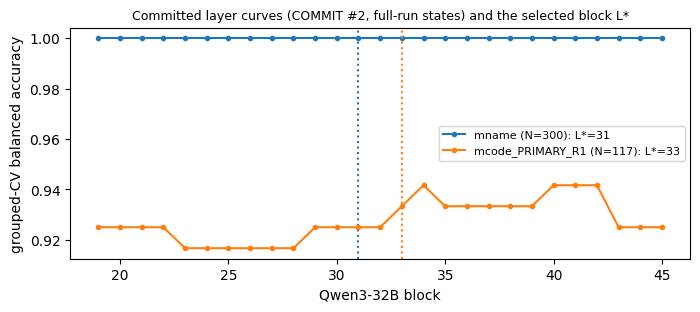

In [11]:
def select_block(curve: dict[int, float], sel: list[int], n_layers: int) -> dict[str, Any]:
    """notebook: the selection rule of layer_curve_parallel (verbatim), applied to the committed curve. The curve itself
    (grouped 10-fold CV balanced accuracy per block) needs every block's states, which the mini data does not hold."""
    best = max(curve.values())
    near = [b for b in sel if best - curve[b] <= 0.01]
    L = min(near, key=lambda b: (abs((b + 1) / n_layers - 0.5), b))
    ceiling = [b for b in sel if curve[b] >= 0.9999]
    rule = "argmax (ties within 0.01 -> nearest depth 0.5)"
    if len(ceiling) == len(sel):
        L = min(ceiling, key=lambda b: (abs((b + 1) / n_layers - 0.5), b))
        rule = "all blocks at ceiling -> nearest depth 0.5"
    return {"curve": curve, "L_star": int(L), "best": best, "tied_blocks": near, "rule": rule,
            "depth_of_L_star": (L + 1) / n_layers}


blocks_rec: dict[str, Any] = {"manifolds": {}}      # notebook: stands in for predictions/commit2.json
for name in DEMO_MANIFOLDS:
    cfg = MODELS["32b"]
    committed = data["metadata"]["layer_curves"][name]
    lc = select_block({int(b): float(v) for b, v in committed["curve"].items()}, cfg["sel_blocks"], cfg["n_layers"])
    assert lc["L_star"] == committed["L_star"]
    blocks_rec["manifolds"][f"32b|{name}"] = {**lc, "n_points": committed["n_points"],
                                              "classes_present": committed["classes_present"],
                                              "ref_block": cfg["ref_block"]}
    logger.info(f"blocks 32b {name}: L*={lc['L_star']} best={lc['best']:.3f} ({lc['rule']})")

fig, ax = plt.subplots(figsize=(8, 3))
for name in DEMO_MANIFOLDS:
    r = blocks_rec["manifolds"][f"32b|{name}"]
    ax.plot(list(r["curve"]), list(r["curve"].values()), marker=".", label=f"{name} (N={r['n_points']}): L*={r['L_star']}")
    ax.axvline(r["L_star"], ls=":", color=ax.lines[-1].get_color())
ax.set_xlabel("Qwen3-32B block")
ax.set_ylabel("grouped-CV balanced accuracy")
ax.set_title("Committed layer curves (COMMIT #2, full-run states) and the selected block L*", fontsize=9)
ax.legend(fontsize=8)
plt.show()

## Stages 7–10: manifold description and reliability (`src/stage_analysis.py`)

These wrappers call the geometry primitives unchanged:
* `describe`: PCA explained variance, classical-MDS stress, and at each k the geodesic g values, classes, nearest banned algorithm, class geodesic matrix, and **unit Dijkstra's rank and g/median**. It also gives the Euclidean-centroid classes, and with `embed=True` an Isomap embedding for the figures.
* `split_half`: the class geodesic matrix from two halves of the paraphrase groups. It reports the Spearman correlation, the Spearman–Brown reliability and the RSA noise ceiling.
* `bootstrap`: resamples paraphrase groups with replacement and recomputes g and classes, giving P(EDGE), class stability and a g/median CI. The original spreads the seed chunks over a 12-process pool; here the same chunks run sequentially, so the results are identical.
* `crossnobis`: split-half cross-validated squared centroid distances, a sensitivity check that is unbiased by noise.

In [12]:
# ---------------------------------------------------------------------------------------------- geometry
def classes_of(g: dict[str, float]) -> tuple[dict[str, str], float]:
    return geometry.classify(g)


def describe(X: np.ndarray, labels: np.ndarray, ks: tuple[int, ...] = KS, embed: bool = False) -> dict[str, Any]:
    present = [a for a in CANON_ORDER if a in set(labels.tolist())]
    nb = [a for a in NB5 if a in present]
    bp = [b for b in B5 if b in present]
    out: dict[str, Any] = {"n_points": int(len(X)), "present": present, "nonbanned_used": nb, "banned_used": bp}
    from sklearn.decomposition import PCA

    pca = PCA(n_components=min(10, len(X) - 1), random_state=0).fit(X)
    out["pca_evr"] = pca.explained_variance_ratio_.tolist()
    D = geometry.squareform(geometry.pdist(X))
    Ym = geometry.classical_mds(D)
    out["mds_points_stress1"] = geometry.stress1(D, Ym)
    cent = np.stack([X[labels == c].mean(0) for c in present])
    Dc = geometry.squareform(geometry.pdist(cent))
    Ymc = geometry.classical_mds(Dc)
    out["mds_centroids_stress1"] = geometry.stress1(Dc, Ymc)
    out["centroid_distance_matrix"] = Dc.tolist()
    emb = {"pca": pca, "mds_points": Ym, "mds_centroids": Ymc, "geo": {}, "D": D}
    for k in ks:
        geo, info = geometry.geodesics(X, k)
        g, near = geometry.g_values(geo, labels, bp, nb)
        cls, med = classes_of(g)
        M = geometry.class_matrix(geo, labels, CANON_ORDER)
        rank = sorted(nb, key=lambda a: g[a]).index(UDIJ) + 1 if UDIJ in nb else None
        out[f"k{k}"] = {**info, "g": g, "nearest_banned": near, "classes": cls, "median": med,
                        "class_geodesic_matrix": M.tolist(), "udij_rank": rank,
                        "udij_ratio": (g[UDIJ] / med) if UDIJ in nb and med > 0 else None}
        emb["geo"][k] = geo
    gc_, nc_ = geometry.g_centroid(X, labels, bp, nb)
    clc, medc = classes_of(gc_)
    out["euclid_centroid"] = {"g": gc_, "nearest_banned": nc_, "classes": clc, "median": medc}
    if embed:
        from sklearn.manifold import Isomap

        iso = Isomap(n_neighbors=K_VERDICT, n_components=2).fit(X)
        emb["isomap"] = (iso, iso.embedding_)
    out["_emb"] = emb
    return out


def split_half(X: np.ndarray, labels: np.ndarray, groups: np.ndarray, k: int) -> dict[str, Any]:
    ug = np.unique(groups)
    thr = ug[len(ug) // 2]
    h1 = groups < thr
    mats = []
    for m in (h1, ~h1):
        geo, _ = geometry.geodesics(X[m], k)
        M = geometry.class_matrix(geo, labels[m], CANON_ORDER)
        mats.append((M + M.T) / 2)
    present = [i for i, a in enumerate(CANON_ORDER) if a in set(labels.tolist())]
    iu = [(i, j) for i, j in itertools.combinations(present, 2)]
    a = [mats[0][i, j] for i, j in iu]
    b = [mats[1][i, j] for i, j in iu]
    rho = float(spearmanr(a, b).statistic)
    sb = 2 * rho / (1 + rho) if rho > -1 else float("nan")
    return {"k": k, "split_threshold_group": int(thr), "spearman_halves": rho, "spearman_brown": sb,
            "noise_ceiling_upper": float(np.sqrt(max(sb, 0.0))), "flag_unreliable": sb < RELIABILITY_FLAG,
            "half_matrices": [m.tolist() for m in mats]}


def _boot_chunk(args: tuple) -> list[dict[str, Any]]:
    X, labels, groups, k, seeds = args
    gm = geometry               # notebook: was `import geometry as gm` (import inside the worker process)
    b5, nb5 = B5, NB5           # notebook: was `from tpg import B5 as b5, NB5 as nb5`

    nb = [a for a in nb5 if a in set(labels.tolist())]
    b5 = [b for b in b5 if b in set(labels.tolist())]
    ug = np.unique(groups)
    out = []
    for s in seeds:
        rng = np.random.default_rng(s)
        gs = rng.choice(ug, size=len(ug), replace=True)
        idx = np.concatenate([np.where(groups == g)[0] for g in gs])
        Xb = X[idx] + rng.normal(0, 1e-9, size=X[idx].shape)
        geo, _ = gm.geodesics(Xb, k)
        g, near = gm.g_values(geo, labels[idx], b5, nb)
        M = gm.class_matrix(geo, labels[idx], list(CANON_ORDER))   # notebook: was list(__import__("common").CANON_ORDER)
        out.append({"g": g, "near": near, "M": ((M + M.T) / 2).tolist()})
    return out


def bootstrap(X: np.ndarray, labels: np.ndarray, groups: np.ndarray, k: int, n_boot: int, full: dict[str, Any],
              seed: int = 0) -> dict[str, Any]:
    seeds = [seed * 100000 + i for i in range(n_boot)]
    chunks = [seeds[i::N_WORKERS] for i in range(N_WORKERS)]
    # notebook: `with _pool() as ex: ... ex.map(_boot_chunk, ...)` -> built-in map over the same chunks (sequential)
    res = [r for part in map(_boot_chunk, [(X, labels, groups, k, c) for c in chunks if c]) for r in part]
    nb = list(full["g"].keys())
    full_cls = full["classes"]
    cls_runs = [classes_of(r["g"])[0] for r in res]
    ratios = [r["g"][UDIJ] / float(np.median(list(r["g"].values()))) for r in res] if UDIJ in nb else []
    ranks = [sorted(nb, key=lambda a: r["g"][a]).index(UDIJ) + 1 for r in res] if UDIJ in nb else []
    return {"n_boot": len(res), "k": k,
            "class_stability": {a: float(np.mean([c[a] == full_cls[a] for c in cls_runs])) for a in nb},
            "edge_probability": {a: float(np.mean([c[a] == "EDGE" for c in cls_runs])) for a in nb},
            "opposite_probability": {a: float(np.mean([c[a] == "OPPOSITE" for c in cls_runs])) for a in nb},
            "nearest_banned_stability": {a: float(np.mean([r["near"][a] == full["nearest_banned"][a] for r in res]))
                                         for a in nb},
            "udij_ratio_ci95": [float(np.quantile(ratios, 0.025)), float(np.quantile(ratios, 0.975))] if ratios
            else None, "udij_rank_distribution": {int(v): ranks.count(v) for v in sorted(set(ranks))},
            "_matrices": [r["M"] for r in res]}


def crossnobis(X: np.ndarray, labels: np.ndarray, groups: np.ndarray) -> dict[str, Any]:
    """Split-half cross-validated squared centroid distances d2(a,b) = (mu_a^A - mu_b^A).(mu_a^B - mu_b^B)."""
    ug = np.unique(groups)
    thr = ug[len(ug) // 2]
    h1 = groups < thr
    present = [a for a in CANON_ORDER if a in set(labels.tolist())]
    muA = {a: X[h1 & (labels == a)].mean(0) for a in present}
    muB = {a: X[~h1 & (labels == a)].mean(0) for a in present}
    D = np.zeros((10, 10))
    for i, a in enumerate(CANON_ORDER):
        for j, b in enumerate(CANON_ORDER):
            if a in present and b in present and a != b:
                D[i, j] = float((muA[a] - muA[b]) @ (muB[a] - muB[b]))
    nb = [a for a in NB5 if a in present]
    g = {a: min(D[CANON_ORDER.index(a), CANON_ORDER.index(b)] for b in B5 if b in present) for a in nb}
    cls, med = classes_of(g)
    return {"d2_cv": D.tolist(), "g": g, "classes": cls, "median": med}

### Landing, robustness, and the per-manifold driver

* `landing_all` runs the landing test for the screen (6), confirmation (9) and pooled (15) survivors.
* `robustness` repeats the classes and the verdict over blocks L*−2 … L*+2 × every k. The mini data stores block L* only, so here it covers the k values at L*; the full run's counts appear in the summary.
* `analyse_manifold` is the per-manifold driver of `stage_analyse("geometry")`. Its by-products (bootstrap matrices, frozen kNN graphs, figure coordinates) go to in-memory dicts instead of `.npy` / `.npz` files.

In [13]:
BOOT_MATS: dict[tuple, np.ndarray] = {}    # notebook: replaces cache/states/boot_{model}_{name}_k{k}.npy
FROZEN_GEO: dict[tuple, dict] = {}         # notebook: replaces cache/states/geo_{model}_{name}_k{k}.npz
COORDS: dict[tuple, dict] = {}             # notebook: replaces figures/coords/{model}_{name}.npz


def landing_all(g: dict[str, float], cls: dict[str, str]) -> dict[str, Any]:
    # notebook: iteration 8's C6 baseline label counts come from the data file (were counted from
    # inputs/e44/data/labelled_C6_baseline.jsonl: sum(1 for r in base if r.get("adj_label") == a))
    base_counts = {a: data["metadata"]["e44_counts"]["C6_baseline"].get(a, 0) for a in g}
    rates = forced_rates_e44()
    out = {}
    for nm, surv in (("screen", SURV_SCREEN), ("confirm", SURV_CONFIRM), ("pooled", SURV_SCREEN + SURV_CONFIRM)):
        surv_ok = [s for s in surv if s in g]
        if not surv_ok:
            out[nm] = {"verdict": "UNTESTABLE (survivor algorithm not in the manifold)"}
            continue
        # notebook: draws=LANDING_DRAWS (the original uses landing()'s default, 10000)
        out[nm] = landing.strip(landing.landing(g, cls, surv_ok, base_counts, rates, draws=LANDING_DRAWS))
    return out


def robustness(Xb: np.ndarray, labels: np.ndarray, blocks: list[int], L: int) -> dict[str, Any]:
    cells = {}
    for b in range(L - 2, L + 3):
        if b not in blocks:
            continue
        X = Xb[:, blocks.index(b)].astype(np.float64)
        nb = [a for a in NB5 if a in set(labels.tolist())]
        bp = [b for b in B5 if b in set(labels.tolist())]
        for k in KS:
            geo, info = geometry.geodesics(X, k)
            g, _ = geometry.g_values(geo, labels, bp, nb)
            cls, _ = classes_of(g)
            lk = landing_all(g, cls)["pooled"]
            cells[f"L{b}_k{k}"] = {"udij_class": cls.get(UDIJ), "classes": cls, "verdict": lk.get("verdict"),
                                   "components": info["components_before_join"]}
    from collections import Counter

    return {"cells": cells, "udij_class_counts": dict(Counter(c["udij_class"] for c in cells.values())),
            "verdict_counts": dict(Counter(c["verdict"] for c in cells.values())), "n_cells": len(cells)}


def analyse_manifold(model_tag: str, name: str, blocks_rec: dict[str, Any]) -> dict[str, Any] | None:
    m = load_manifold(model_tag, name)
    if m is None:
        return None
    cfg = MODELS[model_tag]
    key = f"{model_tag}|{name}"
    L = blocks_rec["manifolds"][key]["L_star"]
    res: dict[str, Any] = {"model": model_tag, "manifold": name, "L_star": L, "ref_block": cfg["ref_block"],
                           "n_points": int(len(m["X"])), "layer_curve": blocks_rec["manifolds"][key]}
    n_boot = N_BOOT_32B if model_tag == "32b" and name in VERDICT_MANIFOLDS[:4] else N_BOOT_OTHER
    for tag_b, b in (("L_star", L), ("ref_block", cfg["ref_block"])):
        if tag_b == "ref_block" and b == L:
            res["ref_block_same_as_L_star"] = True
            continue
        if b not in m["blocks"]:      # notebook: the mini data stores block L* only (M-code: 33, so block 31 is skipped)
            res["ref_block_not_in_mini_data"] = b
            continue
        X = m["X"][:, m["blocks"].index(b)].astype(np.float64)
        d = describe(X, m["labels"], embed=(tag_b == "L_star"))
        emb = d.pop("_emb")
        sec: dict[str, Any] = {"block": b, "describe": d}
        sec["landing"] = {f"k{k}": landing_all(d[f"k{k}"]["g"], d[f"k{k}"]["classes"]) for k in (K_SECOND, K_VERDICT)}
        sec["split_half"] = {f"k{k}": {kk: vv for kk, vv in split_half(X, m["labels"], m["groups"], k).items()
                                       if kk != "half_matrices"} for k in KS}
        if tag_b == "L_star":
            sec["bootstrap"] = {}
            for k in (K_VERDICT, K_SECOND):
                bs = bootstrap(X, m["labels"], m["groups"], k, n_boot, d[f"k{k}"], seed=k)
                mats = bs.pop("_matrices")
                BOOT_MATS[(model_tag, name, k)] = np.array(mats, dtype=np.float32)   # notebook: was np.save(...)
                sec["bootstrap"][f"k{k}"] = bs
            sec["robustness"] = robustness(m["X"], m["labels"], m["blocks"], L)
            sec["crossnobis"] = crossnobis(X, m["labels"], m["groups"])
            mu, sd = X.mean(0), X.std(0) + 1e-8
            dz = describe((X - mu) / sd, m["labels"], ks=(K_VERDICT,))
            dz.pop("_emb")
            sec["zscored"] = {"classes": dz[f"k{K_VERDICT}"]["classes"], "g": dz[f"k{K_VERDICT}"]["g"]}
            # freeze for iteration 10 (out-of-sample placement without refitting)
            for k in (K_SECOND, K_VERDICT):
                G, ncomp, added = geometry.knn_graph(X, k)
                FROZEN_GEO[(model_tag, name, k)] = dict(    # notebook: was np.savez_compressed(STATES_DIR / ...)
                    geo=emb["geo"][k], adjacency=G.toarray().astype(np.float32), X=X.astype(np.float32),
                    labels=m["labels"], point_ids=m["ids"], block=L, readout=m.get("readout", "S-mean"),
                    standardised=False, k=k)
            # figure inputs (2-D coordinates only)
            pca2 = emb["pca"].transform(X)[:, :2]
            iso = emb.get("isomap")
            COORDS[(model_tag, name)] = dict(               # notebook: was np.savez_compressed(... figures/coords ...)
                pca2=pca2, evr=np.array(d["pca_evr"][:2]), mds=emb["mds_points"],
                mds_c=emb["mds_centroids"], iso=iso[1] if iso else np.zeros((0, 2)),
                labels=m["labels"], geo=emb["geo"][K_VERDICT], block=L,
                pca_components=emb["pca"].components_[:2].astype(np.float32),
                pca_mean=emb["pca"].mean_.astype(np.float32))
        res[tag_b] = sec
    v = res["L_star"]["describe"]
    res["summary"] = {f"k{k}": {"udij_class": v[f"k{k}"]["classes"].get(UDIJ), "udij_rank": v[f"k{k}"]["udij_rank"],
                                "udij_ratio": v[f"k{k}"]["udij_ratio"], "udij_nearest_banned":
                                    v[f"k{k}"]["nearest_banned"].get(UDIJ), "classes": v[f"k{k}"]["classes"],
                                "verdict_pooled": res["L_star"]["landing"].get(f"k{k}", {}).get("pooled", {}).get(
                                    "verdict") if k in (K_SECOND, K_VERDICT) else None} for k in KS}
    logger.info(f"[{model_tag} {name}] L*={L} k15 {res['summary']['k15']['classes']} verdict "
                f"{res['summary']['k15']['verdict_pooled']} | k10 {res['summary']['k10']['udij_class']} "
                f"{res['summary']['k10']['verdict_pooled']}")
    return res

## Run the geometry on both manifolds (`stage_analyse("geometry")`)

For each manifold and k, the table shows:
* the class and g value of every non-banned algorithm present. M-code has only IDA* and unit Dijkstra, because they are the only non-banned algorithms with at least 10 verified programs.
* unit Dijkstra's **rank** (1 = nearest the banned five), its **g/median** ratio (< 1 EDGE, > 1 OPPOSITE) and its nearest banned algorithm;
* the **landing verdict** of the 15 survivors at k = 10 and k = 15 (the committed settings), with p_edge / p_opp under the uniform null U.

In [14]:
t0 = time.time()
geo_results: dict[str, Any] = {}           # notebook: stands in for results/geometry_all.json
for model_tag in ("32b",):
    for name in DEMO_MANIFOLDS:            # notebook: the original loops over VERDICT_MANIFOLDS of both models
        if f"{model_tag}|{name}" not in blocks_rec["manifolds"]:
            continue
        r = analyse_manifold(model_tag, name, blocks_rec)
        if r is not None:
            geo_results[f"{model_tag}|{name}"] = r
print(f"geometry stage: {time.time() - t0:.1f} s")

rows = []
for key, r in geo_results.items():
    d = r["L_star"]["describe"]
    for k in KS:
        kd = d[f"k{k}"]
        lk = r["L_star"]["landing"].get(f"k{k}", {}).get("pooled", {})
        rows.append({"manifold": key, "N": d["n_points"], "k": k, "graph components": kd["components_before_join"],
                     **{SHORT[a]: f"{kd['classes'][a][:3]} {kd['g'][a]:.1f}" for a in d["nonbanned_used"]},
                     "uDij rank": f"{kd['udij_rank']}/{len(d['nonbanned_used'])}",
                     "uDij g/median": round(kd["udij_ratio"], 2), "uDij nearest banned": SHORT[kd["nearest_banned"][UDIJ]],
                     "landing (15 survivors)": lk.get("verdict", ""),
                     "p_edge / p_opp (U)": (f"{lk['nulls']['U']['p_edge']:.3f} / {lk['nulls']['U']['p_opp']:.3f}"
                                            if lk.get("nulls") else "")})
pd.DataFrame(rows).fillna("-").set_index(["manifold", "k"])

20:04:20|INFO   |[32b mname] L*=31 k15 {'bibfs': 'EDGE', 'biastar': 'EDGE', 'idastar': 'MIDDLE', 'jps': 'OPPOSITE', 'dijkstra_unit': 'OPPOSITE'} verdict OPPOSITE | k10 OPPOSITE NEITHER


20:04:28|INFO   |[32b mcode_PRIMARY_R1] L*=33 k15 {'idastar': 'OPPOSITE', 'dijkstra_unit': 'EDGE'} verdict EDGE | k10 EDGE EDGE


geometry stage: 23.1 s


N  graph components    BiBFS      BiA*      IDA*       JPS Dijkstra(u) uDij rank  uDij g/median uDij nearest banned landing (15 survivors) p_edge / p_opp (U)
manifold             k                                                                                                                                                                 
32b|mname            5   60                 1  EDG 8.9  EDG 10.4  MID 11.9  OPP 14.0    OPP 14.0       4/5           1.18                  A*                                          
                     10  60                 1  EDG 7.5   EDG 8.8  MID 10.0  OPP 12.4    OPP 10.0       4/5           1.01                  A*                NEITHER      0.753 / 0.247
                     15  60                 1  EDG 7.2   EDG 8.1   MID 9.1  OPP 11.6     OPP 9.9       4/5           1.09                  A*               OPPOSITE      0.967 / 0.033
32b|mcode_PRIMARY_R1 5   36                 2        -         -  OPP 38.7         -    EDG 16.3       1/2           0.59                GBFS                                          
                     10  36                 1        -         -  OPP 24.7         -    EDG 13.4       1/2           0.70                GBFS                   EDGE      0.000 / 1.000
                     15  36                 1        -         -  OPP 21.2         -    EDG 12.0       1/2           0.72                GBFS                   EDGE      0.000 / 1.000

## Lexical regression: do the aliases' *names* drive the M-name geometry? (prediction P4)

Each non-banned algorithm has 3 aliases (for example "bidirectional BFS", "BiBFS", ...), 15 aliases in all. For each alias, **g_alias** is the min over banned algorithms of the mean geodesic distance from that alias's points. g_alias is then correlated with three lexical measures from `results/lexical.json`:
* **L1**: how many banned algorithms' alias regexes match the alias;
* **L2**, **L3**: token-overlap measures.

**P4** passes if Spearman(g_alias, L1) ≤ −0.6 at both k = 10 and k = 15, i.e. aliases that contain banned names sit closer to the banned clusters. The within-algorithm test demeans g and L2 per algorithm and runs all 6^5 = 7,776 exact within-algorithm permutations.

In [15]:
# ---------------------------------------------------------------------------------------------- lexical regression
def _perm_p(x: np.ndarray, y: np.ndarray, n: int = PERM_N, seed: int = 0) -> float:   # notebook: default n was 100000
    rng = np.random.default_rng(seed)
    r0 = spearmanr(x, y).statistic
    rx, ry = rankdata(x), rankdata(y)
    ry = ry - ry.mean()
    P = np.argsort(rng.random((n, len(x))), axis=1)
    rxp = rx[P] - rx.mean()
    rr = (rxp * ry).sum(1) / np.sqrt((rxp ** 2).sum(1) * (ry ** 2).sum())
    return float(np.mean(rr <= r0 + 1e-12)) if r0 < 0 else float(np.mean(rr >= r0 - 1e-12))


def partial_spearman(x: np.ndarray, y: np.ndarray, z: np.ndarray) -> float:
    rx, ry, rz = rankdata(x), rankdata(y), rankdata(z)
    A = np.c_[np.ones(len(rz)), rz]
    ex = rx - A @ np.linalg.lstsq(A, rx, rcond=None)[0]
    ey = ry - A @ np.linalg.lstsq(A, ry, rcond=None)[0]
    den = np.sqrt((ex ** 2).sum() * (ey ** 2).sum())
    return float((ex * ey).sum() / den) if den > 0 else float("nan")


def alias_level(model_tag: str, name: str, L: int) -> dict[str, Any] | None:
    m = load_manifold(model_tag, name)
    if m is None:
        return None
    lex = {"aliases": data["metadata"]["lexical_aliases"]}   # notebook: was read_json(RESULTS / "lexical.json")
    lx = {(r["algorithm"], r["alias_index"]): r for r in lex["aliases"]}
    X = m["X"][:, m["blocks"].index(L)].astype(np.float64)
    out = {}
    key_arr = m["alias"] if name in ("mname", "mlex") else None
    for k in (K_SECOND, K_VERDICT):
        geo, _ = geometry.geodesics(X, k)
        rows = []
        for a in NB5:
            for j in range(3):
                sel = (m["labels"] == a) & (key_arr == j)
                gm = min(float(np.mean(geo[np.ix_(sel, m["labels"] == b)])) for b in B5)
                rows.append({"algorithm": a, "alias_index": j, "g_alias": gm, **{f: lx[(a, j)][f] for f in
                                                                                 ("L1", "L2", "L3", "n_tokens")}})
        g = np.array([r["g_alias"] for r in rows])
        res: dict[str, Any] = {"rows": rows}
        for f in ("L1", "L2", "L3"):
            v = np.array([r[f] for r in rows], dtype=float)
            res[f"spearman_{f}"] = float(spearmanr(g, v).statistic)
            res[f"perm_p_{f}"] = _perm_p(g, v)
            res[f"partial_{f}_given_length"] = partial_spearman(g, v, np.array([r["n_tokens"] for r in rows]))
        # within-algorithm test: demean by algorithm, exact 6^5 within-algorithm permutations of L2
        algs = [r["algorithm"] for r in rows]
        gd = g - np.array([np.mean([g[i] for i in range(15) if algs[i] == algs[t]]) for t in range(15)])
        L2 = np.array([r["L2"] for r in rows])
        L2d = L2 - np.array([np.mean([L2[i] for i in range(15) if algs[i] == algs[t]]) for t in range(15)])
        r0 = float(np.corrcoef(gd, L2d)[0, 1]) if L2d.std() > 0 else float("nan")
        perms = list(itertools.permutations(range(3)))
        cnt, tot = 0, 0
        for combo in itertools.product(perms, repeat=5):
            L2p = np.concatenate([L2d[3 * i:3 * i + 3][list(p)] for i, p in enumerate(combo)])
            r = float(np.corrcoef(gd, L2p)[0, 1]) if L2p.std() > 0 else 0.0
            cnt += r <= r0 + 1e-12
            tot += 1
        res["within_algorithm"] = {"pearson_demeaned_g_L2": r0, "exact_p_lower": cnt / tot, "n_perms": tot}
        out[f"k{k}"] = res
    out["P4_pass"] = all(out[f"k{k}"]["spearman_L1"] <= -0.6 for k in (K_SECOND, K_VERDICT))
    return out


# stage_analyse("lexical"): Qwen3-32B M-name (M-lex and Qwen3-8B are not in the mini data)
t0 = time.time()
lex_results: dict[str, Any] = {}           # notebook: stands in for results/lexical_regression.json
for model_tag in ("32b",):
    for name in ("mname",):
        key = f"{model_tag}|{name}"
        if key in blocks_rec["manifolds"]:
            lex_results[key] = alias_level(model_tag, name, blocks_rec["manifolds"][key]["L_star"])
print(f"lexical regression: {time.time() - t0:.1f} s")

lr = lex_results["32b|mname"]
display(pd.DataFrame([{"k": k, **{f"Spearman(g_alias, {f})": round(lr[k][f"spearman_{f}"], 3) for f in ("L1", "L2", "L3")},
                       "perm p (L1)": lr[k]["perm_p_L1"], "partial L1 | length": round(lr[k]["partial_L1_given_length"], 3),
                       "within-alg. exact p (L2)": round(lr[k]["within_algorithm"]["exact_p_lower"], 3)}
                      for k in ("k10", "k15")]).set_index("k"))
print("P4 pass (Spearman(g_alias, L1) <= -0.6 at k10 and k15):", lr["P4_pass"])
pd.DataFrame(lr["k15"]["rows"]).assign(alias=lambda t: [next(a["alias"] for a in data["metadata"]["lexical_aliases"]
                                                             if a["algorithm"] == r.algorithm and a["alias_index"] == r.alias_index)
                                                        for r in t.itertuples()]).round(3)

lexical regression: 0.6 s


,"Spearman(g_alias, L1)","Spearman(g_alias, L2)","Spearman(g_alias, L3)",perm p (L1),partial L1 | length,within-alg. exact p (L2)
k,,,,,,
k10,-0.604,-0.334,-0.709,0.00994,-0.617,0.274
k15,-0.650,-0.382,-0.752,0.00503,-0.669,0.269


P4 pass (Spearman(g_alias, L1) <= -0.6 at k10 and k15): True


,algorithm,alias_index,g_alias,L1,L2,L3,n_tokens,alias
0,bibfs,0,7.356,1,0.067,0.333,3,bidirectional BFS
1,bibfs,1,7.116,1,0.576,0.500,5,bidirectional breadth-first search
2,bibfs,2,7.057,1,0.408,0.400,10,a breadth-first search run from both start and goal
3,biastar,0,7.747,1,0.333,0.600,5,bidirectional A* search
4,biastar,1,8.117,1,0.037,0.400,4,bidirectional A*
5,biastar,2,8.375,1,0.054,0.182,10,A* run from both start and goal at once
6,idastar,0,8.042,1,0.778,0.400,4,IDA* search
7,idastar,1,10.101,2,0.571,0.333,8,iterative deepening A* (IDA*)
8,idastar,2,8.306,1,0.522,0.500,7,IDA* with a Manhattan heuristic
9,jps,0,10.649,0,0.294,0.200,3,jump point search


## RSA: which model RDM does each manifold's class geometry follow? (prediction P7)

The neural RDM is the symmetrised class geodesic matrix at k = 15, over the classes present. It is compared with fixed **model RDMs**, precomputed by the CPU stages and stored in the data file:
* **R_lex**: alias character 3-grams;
* **R_beh**: behavioural distance between the algorithms' expansion-order traces on 40 probe grids; **R_beh_order** and **R_DS** are its two components;
* **R_surface**: AST 4-gram Jaccard distance between the verified programs;
* **R_len**: stimulus-length difference;
* **R_desc_lex**: description lexical overlap.

The p value is **exact**, over all n! permutations of the class labels: 10! = 3,628,800 for M-name, 6! = 720 for M-code. In the full run, M-name follows R_lex (ρ 0.46, p 0.003), while M-code follows R_beh (ρ 0.64, p 0.018) and R_surface (ρ 0.67, p 0.010). The bootstrap CIs of the ρ differences reuse the bootstrap matrices from the geometry step.

`surface_rdm()`, which builds R_surface and R_len, needs the Qwen3-32B tokenizer and the full program sets, so its output is read from the data file.

In [16]:
# ---------------------------------------------------------------------------------------------- RSA
_PERMS: dict[int, np.ndarray] = {}


def _perms(n: int) -> np.ndarray:
    if n not in _PERMS:
        _PERMS[n] = np.array(list(itertools.permutations(range(n))), dtype=np.int8)
    return _PERMS[n]


def mantel_exact(neural: np.ndarray, model: np.ndarray) -> dict[str, Any]:
    """Spearman over the upper triangle; exact p over all n! condition-label permutations (one-sided, >=)."""
    n = len(neural)
    iu = np.triu_indices(n, 1)
    rv = rankdata(neural[iu])
    rv = rv - rv.mean()
    RM = np.zeros((n, n))
    RM[iu] = rankdata(model[iu])
    RM = RM + RM.T
    rm = RM[iu] - RM[iu].mean()
    rho = float((rv * rm).sum() / np.sqrt((rv ** 2).sum() * (rm ** 2).sum()))
    P = _perms(n)
    flat = RM.ravel()
    mean_r = RM[iu].mean()
    den = np.sqrt((rv ** 2).sum() * (rm ** 2).sum())
    ge = 0
    for s in range(0, len(P), 200000):
        ch = P[s:s + 200000].astype(np.int64)
        vals = flat[ch[:, iu[0]] * n + ch[:, iu[1]]] - mean_r
        r = (vals @ rv) / den
        ge += int(np.sum(r >= rho - 1e-12))
    return {"rho": rho, "p_exact": ge / len(P), "n_perms": int(len(P)), "n_pairs": int(len(rv))}


def model_rdms(manifold: str) -> dict[str, np.ndarray]:
    # notebook: the matrices come from data["metadata"]["model_rdms"], copied from results/behavioural_distance.json
    # (R_beh = d_beh_lambda0.5, R_beh_order = d_order, R_DS = d_DS), results/lexical.json (R_lex),
    # results/surface_rdm.json (R_surface, R_len per manifold) and data/descriptions_v0.json (R_desc_lex)
    R = data["metadata"]["model_rdms"]
    out = {"R_lex": np.array(R["R_lex"]), "R_beh": np.array(R["R_beh"]),
           "R_beh_order": np.array(R["R_beh_order"]), "R_DS": np.array(R["R_DS"])}
    out["R_surface"] = np.array(R["R_surface"])
    if manifold in R.get("R_len", {}):
        out["R_len"] = np.array(R["R_len"][manifold])
    out["R_desc_lex"] = np.array(R["R_desc_lex"])
    return out


def rsa(geo_results: dict[str, Any]) -> dict[str, Any]:
    out: dict[str, Any] = {}
    for key, r in geo_results.items():
        if r is None:
            continue
        model_tag, name = key.split("|")
        d = r["L_star"]["describe"]
        M = np.array(d[f"k{K_VERDICT}"]["class_geodesic_matrix"])
        M = (M + M.T) / 2
        present = [i for i, a in enumerate(CANON_ORDER) if a in d["present"]]
        Mn = M[np.ix_(present, present)]
        mr = model_rdms("mcode" if name.startswith("mcode") else name)
        sh = r["L_star"]["split_half"][f"k{K_VERDICT}"]
        res = {"present": [CANON_ORDER[i] for i in present], "noise_ceiling_upper": sh["noise_ceiling_upper"],
               "split_half_spearman_brown": sh["spearman_brown"], "models": {}}
        for mn, R in mr.items():
            Rm = R[np.ix_(present, present)]
            if not np.isfinite(Rm).all():
                continue
            res["models"][mn] = mantel_exact(Mn, Rm)
        # bootstrap CIs of rho differences from the stored bootstrap matrices
        if (model_tag, name, K_VERDICT) in BOOT_MATS:   # notebook: was bp = STATES_DIR / f"boot_..._k{K_VERDICT}.npy"
            mats = BOOT_MATS[(model_tag, name, K_VERDICT)]
            iu = np.triu_indices(len(present), 1)
            diffs = {}
            for a_, b_ in (("R_lex", "R_beh"), ("R_beh", "R_lex"), ("R_surface", "R_beh")):
                if a_ in mr and b_ in mr:
                    Ra = mr[a_][np.ix_(present, present)][iu]
                    Rb = mr[b_][np.ix_(present, present)][iu]
                    vals = []
                    for Mb in mats:
                        v = np.asarray(Mb)[np.ix_(present, present)][iu]
                        if not np.isfinite(v).all():
                            continue
                        vals.append(spearmanr(v, Ra).statistic - spearmanr(v, Rb).statistic)
                    if vals:
                        diffs[f"{a_}-{b_}"] = {"mean": float(np.mean(vals)),
                                               "ci95": [float(np.quantile(vals, 0.025)),
                                                        float(np.quantile(vals, 0.975))], "n": len(vals)}
            res["rho_differences_bootstrap"] = diffs
        if name.startswith("mcode") and "R_surface" in mr and "R_len" in mr:
            iu = np.triu_indices(len(present), 1)
            v = Mn[iu]
            rb = mr["R_beh"][np.ix_(present, present)][iu]
            z1 = mr["R_surface"][np.ix_(present, present)][iu]
            res["partial_beh_given_surface"] = partial_spearman(v, rb, z1)
        out[key] = res
        logger.info(f"RSA {key}: " + ", ".join(f"{k} {v['rho']:.2f} (p {v['p_exact']:.4f})"
                                               for k, v in res["models"].items()))
    return out


# stage_analyse("rsa"): surface_rdm() is precomputed (see above); name_evocation() needs M-desc / M-lex states at
# block 31, which the mini data does not hold (its full-run values are printed in the summary)
t0 = time.time()
rsa_results = rsa(geo_results)             # notebook: stands in for results/rsa.json
print(f"RSA: {time.time() - t0:.1f} s")
pd.DataFrame({key: {mn: f"{v['rho']:.2f} (p {v['p_exact']:.3f})" for mn, v in r["models"].items()}
              for key, r in rsa_results.items()}).T

20:04:39|INFO   |RSA 32b|mname: R_lex 0.39 (p 0.0028), R_beh 0.31 (p 0.0250), R_beh_order 0.14 (p 0.1752), R_DS 0.50 (p 0.0048), R_surface -0.08 (p 0.7005), R_len 0.31 (p 0.0345), R_desc_lex 0.58 (p 0.0001)


20:04:40|INFO   |RSA 32b|mcode_PRIMARY_R1: R_lex 0.12 (p 0.3306), R_beh 0.86 (p 0.0028), R_beh_order 0.68 (p 0.0194), R_DS 0.68 (p 0.0056), R_surface 0.85 (p 0.0014), R_len 0.90 (p 0.0014), R_desc_lex 0.90 (p 0.0028)


RSA: 11.0 s


,R_lex,R_beh,R_beh_order,R_DS,R_surface,R_len,R_desc_lex
32b|mname,0.39 (p 0.003),0.31 (p 0.025),0.14 (p 0.175),0.50 (p 0.005),-0.08 (p 0.700),0.31 (p 0.035),0.58 (p 0.000)
32b|mcode_PRIMARY_R1,0.12 (p 0.331),0.86 (p 0.003),0.68 (p 0.019),0.68 (p 0.006),0.85 (p 0.001),0.90 (p 0.001),0.90 (p 0.003)


## Per-program placement on the M-code frame (prediction P8)

`oos` places a new point x on a frozen manifold without refitting. Its geodesic distance to frame point j is

  min over x's k nearest frame neighbours n of ( ‖x − n‖ + geo(n, j) ),

and x is assigned to the algorithm with the smallest mean distance.

The gate **G_place** requires leave-one-out accuracy ≥ 0.70: each frame program is held out, the graph is rebuilt without it, and the program is placed back. In the full run the 15 survivor programs are then placed one by one (15/15 EDGE). Their states are not in the mini data, so here placement runs only through the LOO gate and the frame's own unit-Dijkstra LOO g values.

In [17]:
# ---------------------------------------------------------------------------------------------- placement
def oos(x: np.ndarray, F: np.ndarray, geo: np.ndarray, k: int) -> np.ndarray:
    d = np.linalg.norm(F - x, axis=1)
    nn = np.argsort(d)[:k]
    return np.min(d[nn][:, None] + geo[nn], axis=0)


def _loo_one(args: tuple) -> tuple[int, str]:
    i, F, labels, k = args
    gm = geometry               # notebook: was `import geometry as gm` (import inside the worker process)

    keep = np.ones(len(F), bool)
    keep[i] = False
    geo, _ = gm.geodesics(F[keep], k)
    dv = oos(F[i], F[keep], geo, k)
    lab = labels[keep]
    algs = sorted(set(lab.tolist()))
    means = {a: float(dv[lab == a].mean()) for a in algs}
    return i, min(means, key=means.get)


def placement(model_tag: str, frame_name: str, L: int, k: int = K_VERDICT) -> dict[str, Any] | None:
    m = load_manifold(model_tag, frame_name)
    if m is None:
        return None
    ro = m["readout"]
    F = m["X"][:, m["blocks"].index(L)].astype(np.float64)
    labels = m["labels"]
    geo, _ = geometry.geodesics(F, k)
    nb = [a for a in NB5 if a in set(labels.tolist())]
    g_frame, _ = geometry.g_values(geo, labels, [b for b in B5 if b in set(labels.tolist())], nb)
    cls_frame, med = classes_of(g_frame)
    # notebook: `with _pool() as ex: loo = dict(ex.map(...))` -> built-in map (sequential)
    loo = dict(map(_loo_one, [(i, F, labels, k) for i in range(len(F))]))
    acc = float(np.mean([loo[i] == labels[i] for i in range(len(F))]))
    # notebook: the original now loads the SURV / BASE / DISOBEY program states from cache/states/mcode_32b.npz and
    # data/mcode_sets.json["placement"], and places each one with oos(). Those states are not in the mini data.
    rows = []
    ud = [r for r in rows if r["set"] == "SURV" and r["label"] == UDIJ]
    n_edge = sum(r["class"] == "EDGE" for r in ud)
    base = [r for r in rows if r["set"] == "BASE"]
    # LOO g of frame uDij programs for the descriptive comparison
    frame_ud_g = []
    for i in np.where(labels == UDIJ)[0]:
        keep = np.ones(len(F), bool)
        keep[i] = False
        g2, _ = geometry.geodesics(F[keep], k)
        dv = oos(F[i], F[keep], g2, k)
        frame_ud_g.append(min(float(dv[labels[keep] == b].mean()) for b in B5 if (labels[keep] == b).any()))
    mw = None
    if ud and frame_ud_g:
        mw = mannwhitneyu([r["g_x"] for r in ud], frame_ud_g).pvalue
    return {"frame": frame_name, "model": model_tag, "block": L, "k": k, "readout": ro,
            "G_place": {"loo_accuracy": acc, "gate": LOO_GATE, "pass": acc >= LOO_GATE},
            "frame_g": g_frame, "frame_classes": cls_frame, "frame_median": med,
            "base_accuracy_own_label": float(np.mean([r["nearest_algorithm"] == r["label"] for r in base]))
            if base else None,
            "udij_survivors": {"n": len(ud), "n_edge": n_edge, "share_edge": n_edge / len(ud) if ud else None,
                               "wilson95": wilson_ci(n_edge, len(ud)) if ud else None,
                               "share_nearest_banned": float(np.mean([r["nearest_algorithm"] in B5 for r in ud]))
                               if ud else None,
                               "nearest_algorithm_counts": {a: sum(r["nearest_algorithm"] == a for r in ud)
                                                            for a in CANON_ORDER},
                               "mannwhitney_p_vs_frame_udij_loo": mw,
                               "frame_udij_loo_g_median": float(np.median(frame_ud_g)) if frame_ud_g else None,
                               "survivor_g_median": float(np.median([r["g_x"] for r in ud])) if ud else None},
            "P8_pass": (n_edge / len(ud) > 0.5) if ud and acc >= LOO_GATE else None,
            "rows": rows, "_loo": loo}   # notebook: `_loo` (per-program LOO predictions) kept for the table below


# stage_analyse("placement"): the PRIMARY R1 frame (R2 and the Qwen3-32B-only frame are not in the mini data)
t0 = time.time()
pl_results: dict[str, Any] = {}            # notebook: stands in for results/placement.json
for model_tag in ("32b",):
    for frame in ("mcode_PRIMARY_R1",):
        key = f"{model_tag}|{frame}"
        if key in blocks_rec["manifolds"]:
            r = placement(model_tag, frame, blocks_rec["manifolds"][key]["L_star"])
            if r:
                pl_results[key] = r
                logger.info(f"placement {key}: LOO {r['G_place']['loo_accuracy']:.2f}; uDij survivors "
                            f"EDGE {r['udij_survivors']['n_edge']}/{r['udij_survivors']['n']}")
print(f"placement: {time.time() - t0:.1f} s")
r = pl_results["32b|mcode_PRIMARY_R1"]
print("G_place:", r["G_place"], "| frame classes:", r["frame_classes"],
      "| median LOO g of the frame's unit-Dijkstra programs:", round(r["udij_survivors"]["frame_udij_loo_g_median"], 2))
_m = load_manifold("32b", "mcode_PRIMARY_R1")
pd.crosstab(pd.Series(_m["labels"], name="true label"),
            pd.Series([r["_loo"][i] for i in range(len(_m["labels"]))], name="LOO placement"))

20:04:40|INFO   |placement 32b|mcode_PRIMARY_R1: LOO 0.78; uDij survivors EDGE 0/0


placement: 0.1 s
G_place: {'loo_accuracy': 0.7777777777777778, 'gate': 0.7, 'pass': True} | frame classes: {'idastar': 'OPPOSITE', 'dijkstra_unit': 'EDGE'} | median LOO g of the frame's unit-Dijkstra programs: 11.16


LOO placement,astar,bfs,dfs,dijkstra_unit,gbfs,idastar
true label,,,,,,
astar,1,0,0,0,5,0
bfs,0,6,0,0,0,0
dfs,0,0,6,0,0,0
dijkstra_unit,0,0,0,4,2,0
gbfs,1,0,0,0,5,0
idastar,0,0,0,0,0,6


## Stage 11: figures in activation coordinates (`src/stage_figures.py`)

All plots are drawn in **actual activation coordinates**, not as summary bars:
* **(a) PCA** of the residual states. Centroids are sized and coloured by how often iteration 8's Qwen3-32B *implemented* each algorithm: left, with no ban; right, under the ban (screen + confirmation). Banned algorithms have a red outline.
* **(b) classical MDS** of the points and of the class centroids.
* **(c) Isomap** at k = 15, with the **geodesic path** from unit Dijkstra to its nearest banned algorithm.

Each figure is also saved as PDF + PNG under `figures/`.

In [18]:
FIG = Path("figures")             # notebook: was ROOT / "figures"
FIG.mkdir(exist_ok=True)
COL = dict(zip(CANON_ORDER, plt.cm.tab10(np.linspace(0, 1, 10))))
TITLES = {"mname": "M-name (alias prompts, S-mean)", "mdesc": "M-desc (name-free descriptions, S-mean)",
          "mlex": "M-lex (alias minus neutral twin, S-mean delta)",
          "mcode_PRIMARY_R1": "M-code PRIMARY (mean over code tokens, R1)",
          "mcode_PRIMARY_R2": "M-code PRIMARY (pop-position token, R2)",
          "mcode_M32_R1": "M-code Qwen3-32B-only frame (R1)", "mcode_M8_R1": "M-code Qwen3-8B-only frame (R1)",
          "mcode_PRIMARY_R1g": "M-code PRIMARY (R1 without massive tokens)",
          "mcode_PRIMARY_R3": "M-code PRIMARY (16th code token, R3: negative control)"}


def _save(fig: Any, name: str) -> None:
    fig.savefig(FIG / f"{name}.pdf", bbox_inches="tight")
    fig.savefig(FIG / f"{name}.png", dpi=150, bbox_inches="tight")
    plt.show()                    # notebook: was plt.close(fig) -- show the figure inline instead


def counts() -> tuple[Counter, Counter]:
    # notebook: iteration 8's labelled C6 baseline and ban (screen + confirm) counts come from the data file
    # (were Counter(r.get("adj_label")) over inputs/e44/data/labelled_C6_{baseline,ban,confirm}.jsonl)
    c = data["metadata"]["e44_counts"]
    base = Counter(c["C6_baseline"])
    ban = Counter(c["C6_ban_screen_plus_confirm"])
    return base, ban


def _overlay(model_tag: str, name: str, z: Any) -> tuple[np.ndarray | None, str]:
    # notebook: the original projects the 7 ban-prompt states (M-name / M-desc; cache/states/ban_32b.npz) or the 15
    # unit-Dijkstra survivor programs (M-code; cache/states/mcode_32b.npz) into the PCA plane. Neither is in the mini
    # data, so M-name falls back to the label-level ring of the 15 survivors and M-code draws no overlay.
    return None, ""


def manifold_figs(model_tag: str, name: str, geo_res: dict[str, Any]) -> None:
    z = COORDS.get((model_tag, name))     # notebook: was np.load(FIG / "coords" / f"{model_tag}_{name}.npz")
    if z is None:
        return
    labels = z["labels"]
    L = int(z["block"])
    present = [a for a in CANON_ORDER if a in set(labels.tolist())]
    base, ban = counts()
    cfg = MODELS[model_tag]
    prec = "nf4" if model_tag == "32b" else "bf16"
    mdl = "Qwen3-32B" if model_tag == "32b" else "Qwen3-8B"
    readout = "SPEC-token mean (S-mean)" if not name.startswith("mcode") else TITLES[name].split("(")[-1].rstrip(")")
    cap = f"{mdl} {prec}, block {L}, readout {readout}, N={len(labels)}"
    P = z["pca2"]
    evr = z["evr"]
    Q, qlab = _overlay(model_tag, name, z)
    fig, axes = plt.subplots(1, 2, figsize=(14, 6))
    for ax, (cnt, ttl) in zip(axes, ((base, "C6 baseline implemented counts"), (ban, "C6 ban implemented counts "
                                                                                    "(screen + confirm)"))):
        for a in present:
            s = labels == a
            ax.scatter(P[s, 0], P[s, 1], s=10, color=COL[a], alpha=0.35)
        vmax = max(1, max(cnt.get(a, 0) for a in present))
        for a in present:
            c = P[labels == a].mean(0)
            n = cnt.get(a, 0)
            ax.scatter([c[0]], [c[1]], s=60 + 40 * np.sqrt(n + 1), c=[[n / vmax]], cmap="viridis", vmin=0, vmax=1,
                       edgecolors="red" if a in B5 else "black", linewidths=2.5 if a in B5 else 1.0, zorder=5)
            ax.annotate(f"{SHORT[a]} ({n})", c, fontsize=8, xytext=(4, 4), textcoords="offset points")
        if Q is not None:
            mk = "*" if not name.startswith("mcode") else "x"
            ax.scatter(Q[:, 0], Q[:, 1], marker=mk, s=110 if mk == "*" else 45, color="black", label=qlab, zorder=6)
            ax.legend(loc="best", fontsize=8)
        elif not name.startswith("mcode"):
            c = P[labels == UDIJ].mean(0) if UDIJ in present else None
            if c is not None:
                th = np.linspace(0, 2 * np.pi, 15, endpoint=False)
                r = 0.04 * (P.max() - P.min())
                ax.scatter(c[0] + r * np.cos(th), c[1] + r * np.sin(th), s=12, marker="o", facecolors="none",
                           edgecolors="black", label="15 unit-Dijkstra survivors (label-level)")
                ax.legend(loc="best", fontsize=8)
        ax.set_xlabel(f"PC1 ({100 * evr[0]:.1f}% var.)")
        ax.set_ylabel(f"PC2 ({100 * evr[1]:.1f}% var.)")
        ax.set_title(ttl, fontsize=10)
    fig.suptitle(f"(a) PCA of residual states: {TITLES[name]}\n{cap}; banned (red outline): "
                 f"{', '.join(SHORT[b] for b in B5)}", fontsize=10)
    _save(fig, f"pca_{model_tag}_{name}")
    # (b) MDS
    d = geo_res["L_star"]["describe"]
    fig, axes = plt.subplots(1, 2, figsize=(13, 5.5))
    Ym = z["mds"]
    for a in present:
        s = labels == a
        axes[0].scatter(Ym[s, 0], Ym[s, 1], s=10, color=COL[a], label=SHORT[a], alpha=0.6)
    axes[0].legend(fontsize=7, ncol=2)
    axes[0].set_title(f"classical MDS of the {len(labels)} points (stress-1 {d['mds_points_stress1']:.2f})", fontsize=10)
    Yc = z["mds_c"]
    for i, a in enumerate(present):
        axes[1].scatter([Yc[i, 0]], [Yc[i, 1]], s=120, color=COL[a], edgecolors="red" if a in B5 else "black",
                        linewidths=2.5 if a in B5 else 1)
        axes[1].annotate(SHORT[a], Yc[i], fontsize=9, xytext=(5, 5), textcoords="offset points")
    axes[1].set_title(f"classical MDS of the {len(present)} centroids (stress-1 {d['mds_centroids_stress1']:.2f})",
                      fontsize=10)
    for ax in axes:
        ax.set_xlabel("MDS 1")
        ax.set_ylabel("MDS 2")
    fig.suptitle(f"(b) {TITLES[name]} - {cap}", fontsize=10)
    _save(fig, f"mds_{model_tag}_{name}")
    # (c) Isomap with geodesic path uDij -> nearest banned
    Y = z["iso"]
    if len(Y):
        geo = z["geo"]
        fig, ax = plt.subplots(figsize=(8, 7))
        for a in present:
            s = labels == a
            ax.scatter(Y[s, 0], Y[s, 1], s=12, color=COL[a], label=SHORT[a], alpha=0.7,
                       edgecolors="red" if a in B5 else "none", linewidths=0.6)
        kd = d[f"k{K_VERDICT}"]
        if UDIJ in present:
            nb = kd["nearest_banned"][UDIJ]
            iu = np.where(labels == UDIJ)[0]
            ib = np.where(labels == nb)[0]
            sub = geo[np.ix_(iu, ib)]
            i, j = np.unravel_index(np.argmin(sub), sub.shape)
            X = FROZEN_GEO[(model_tag, name, K_VERDICT)]   # notebook: was np.load(STATES_DIR / f"geo_..._k{K_VERDICT}.npz")
            G = X["adjacency"]
            _, pred = shortest_path(G, method="D", directed=False, indices=[iu[i]], return_predecessors=True)
            path, cur = [], ib[j]
            while cur >= 0 and cur != iu[i]:
                path.append(cur)
                cur = pred[0, cur]
            path.append(iu[i])
            ax.plot(Y[path, 0], Y[path, 1], "k-", lw=1.5, label=f"geodesic {SHORT[UDIJ]} -> {SHORT[nb]}")
            ttl = (f"class(uDij)={kd['classes'][UDIJ]}, g={kd['g'][UDIJ]:.2f}, median {kd['median']:.2f}, "
                   f"rank {kd['udij_rank']}/{len(kd['g'])}")
        else:
            ttl = "unit Dijkstra not in this manifold"
        ax.legend(fontsize=7, ncol=2)
        ax.set_xlabel("Isomap 1")
        ax.set_ylabel("Isomap 2")
        ax.set_title(f"(c) Isomap k={K_VERDICT}: {TITLES[name]}\n{cap}; {ttl}", fontsize=9)
        _save(fig, f"isomap_{model_tag}_{name}")
    _ = cfg


def class_table(geo_all: dict[str, Any]) -> None:
    rows, cells, txt = [], [], []
    cmap = {"EDGE": 0, "MIDDLE": 1, "OPPOSITE": 2}
    for key, r in geo_all.items():
        if r is None:
            continue
        kd = r["L_star"]["describe"][f"k{K_VERDICT}"]
        rows.append(f"{key} (L{r['L_star']['block']})")
        cells.append([cmap.get(kd["classes"].get(a), np.nan) for a in NB5])
        txt.append([(f"{kd['classes'][a][:3]}\n{kd['g'][a] / kd['median']:.2f}" if a in kd["classes"] else "not run")
                    for a in NB5])
    if not rows:
        return
    fig, ax = plt.subplots(figsize=(9, 0.55 * len(rows) + 1.5))
    ax.imshow(np.array(cells, dtype=float), cmap="coolwarm", vmin=0, vmax=2, aspect="auto")
    for i in range(len(rows)):
        for j in range(5):
            ax.text(j, i, txt[i][j], ha="center", va="center", fontsize=7,
                    fontweight="bold" if NB5[j] == UDIJ else "normal")
    ax.set_xticks(range(5), [SHORT[a] for a in NB5])
    ax.set_yticks(range(len(rows)), rows, fontsize=7)
    ax.set_title(f"EDGE / MIDDLE / OPPOSITE of the non-banned algorithms (k={K_VERDICT}, cell = class, g/median)",
                 fontsize=9)
    _save(fig, "class_table")


def rdm_figs() -> None:
    rs = rsa_results                      # notebook: was read_json(RESULTS / "rsa.json")
    # notebook: behavioural_distance.json / lexical.json / surface_rdm.json -> the same matrices in data["metadata"]
    R, bm = data["metadata"]["model_rdms"], data["metadata"]["behavioural"]
    beh = {"d_beh_lambda0.5": R["R_beh"], "behavioural_coordinates_mds": bm["coordinates_mds"],
           "behavioural_mds_stress1": bm["mds_stress1"]}
    lex = {"R_lex": R["R_lex"]}
    mats = {"R_beh (behavioural)": np.array(beh["d_beh_lambda0.5"]), "R_lex (alias 3-grams)": np.array(lex["R_lex"])}
    mats["R_surface (AST 4-grams)"] = np.array(R["R_surface"])
    geo_all = geo_results                 # notebook: was read_json(RESULTS / "geometry_all.json")
    for key in ("32b|mname", "32b|mdesc", "32b|mlex", "32b|mcode_PRIMARY_R1"):
        if key in geo_all:
            M = np.array(geo_all[key]["L_star"]["describe"][f"k{K_VERDICT}"]["class_geodesic_matrix"])
            M = (M + M.T) / 2
            np.fill_diagonal(M, 0)
            r = rs.get(key, {}).get("models", {})
            lab = f"{key} neural; rho beh {r.get('R_beh', {}).get('rho', float('nan')):.2f}, lex " \
                  f"{r.get('R_lex', {}).get('rho', float('nan')):.2f}"
            mats[lab] = M
    n = len(mats)
    fig, axes = plt.subplots(2, (n + 1) // 2, figsize=(4.2 * ((n + 1) // 2), 8.5))
    for ax, (t, M) in zip(axes.ravel(), mats.items()):
        ax.imshow(np.nan_to_num(M), cmap="magma")
        ax.set_xticks(range(10), [SHORT[a] for a in CANON_ORDER], rotation=90, fontsize=7)
        ax.set_yticks(range(10), [SHORT[a] for a in CANON_ORDER], fontsize=7)
        ax.set_title(t, fontsize=7)
    for ax in axes.ravel()[n:]:
        ax.axis("off")
    _save(fig, "rdms")
    Y = beh["behavioural_coordinates_mds"]
    fig, ax = plt.subplots(figsize=(6, 5))
    for a in CANON_ORDER:
        ax.scatter([Y[a][0]], [Y[a][1]], s=120, color=COL[a], edgecolors="red" if a in B5 else "black",
                   linewidths=2.5 if a in B5 else 1)
        ax.annotate(SHORT[a], Y[a], xytext=(5, 5), textcoords="offset points")
    ax.set_title(f"Behavioural coordinates, not activations: classical MDS of d_beh\n(expansion-order traces of the "
                 f"15 T1 references on 40 probe grids; stress-1 {beh['behavioural_mds_stress1']:.2f})", fontsize=9)
    ax.set_xlabel("behavioural MDS 1")
    ax.set_ylabel("behavioural MDS 2")
    _save(fig, "behavioural_mds")


def lexical_fig() -> None:
    lr = lex_results                      # notebook: was read_json(RESULTS / "lexical_regression.json")
    r = lr.get("32b|mname")
    if not r:
        return
    fig, axes = plt.subplots(1, 2, figsize=(11, 4.5))
    for ax, k in zip(axes, ("k10", "k15")):
        rows = r[k]["rows"]
        for row in rows:
            ax.scatter(row["L1"] + np.random.default_rng(len(row["alias"] if "alias" in row else "") + row[
                "alias_index"]).uniform(-0.08, 0.08), row["g_alias"], color=COL[row["algorithm"]], s=50)
        for a in NB5:
            ax.scatter([], [], color=COL[a], label=SHORT[a])
        ax.set_xlabel("L1 = banned algorithms whose alias regex matches the alias")
        ax.set_ylabel("g_alias (min mean geodesic to a banned algorithm)")
        ax.set_title(f"M-name alias level, {k}: Spearman {r[k]['spearman_L1']:.2f} (perm p {r[k]['perm_p_L1']:.4f})",
                     fontsize=9)
        ax.legend(fontsize=7)
    _save(fig, "lexical_alias_level_32b")

### M-name (alias prompts)

The ten algorithms separate cleanly by name; M-name's committed layer curve is at ceiling at every block. Read panel (c) for the key point: in the full run, unit Dijkstra sits on the far side of the non-banned group from the banned five, so its geodesic path to the nearest banned cluster (A*) is long.

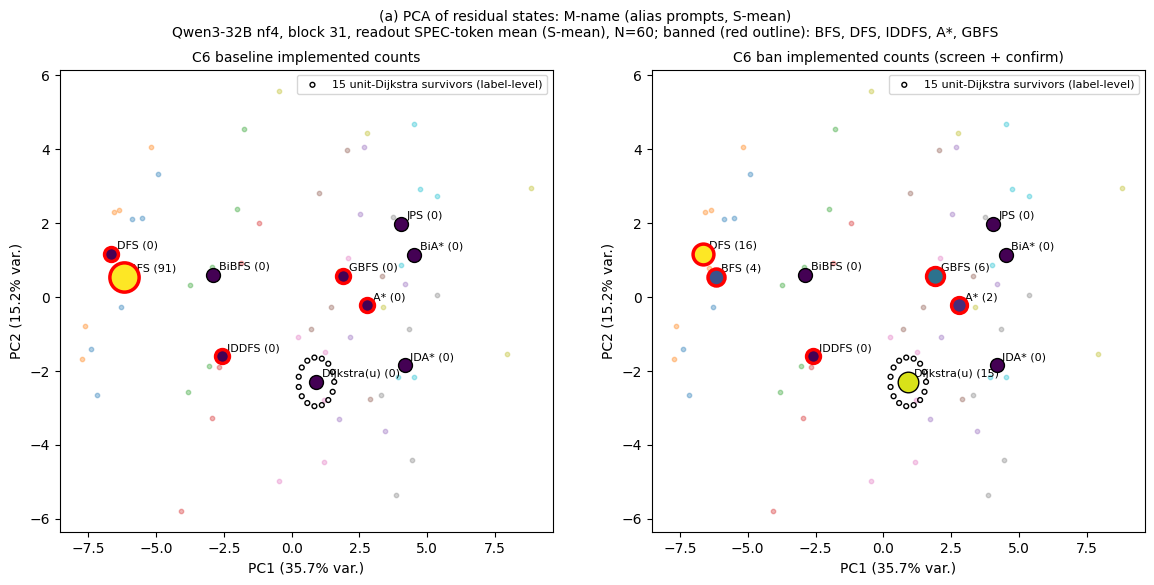

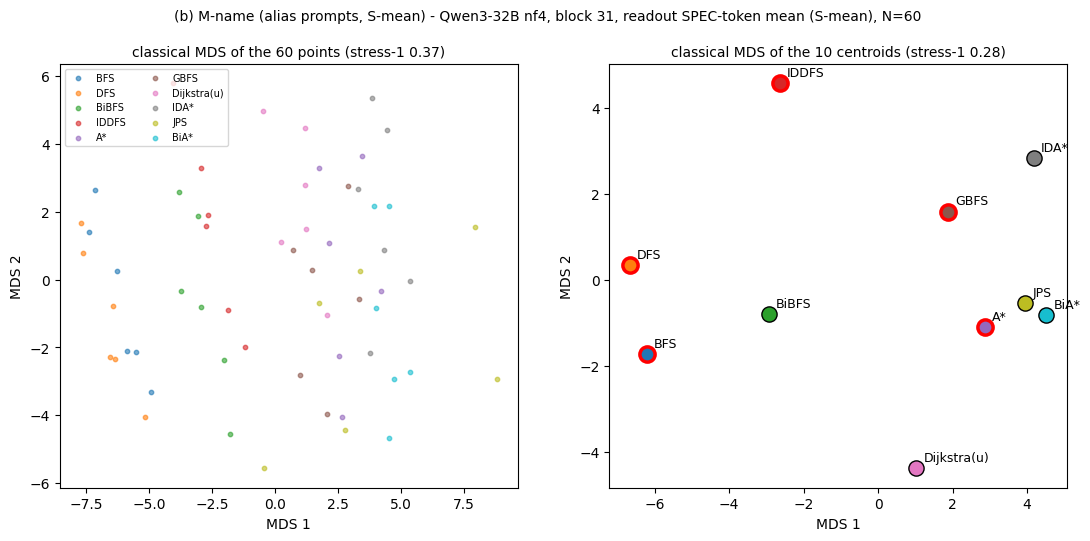

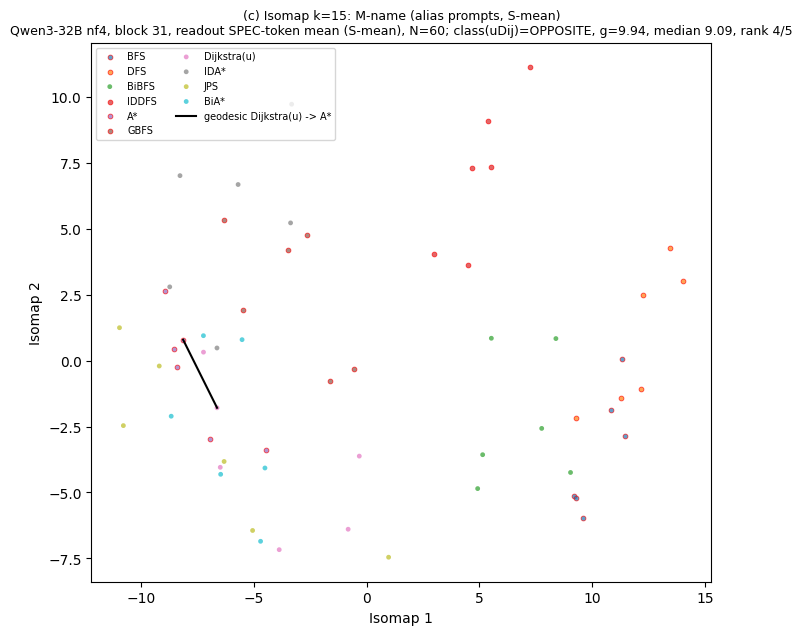

In [19]:
# stage_figures(): one manifold_figs call per model x manifold (here one cell each, without the per-figure try/except)
manifold_figs("32b", "mname", geo_results["32b|mname"])

### M-code PRIMARY R1 (name-scrubbed programs)

Only six algorithms have at least 10 verified programs: the five banned ones except IDDFS, plus unit Dijkstra and IDA*. Unit Dijkstra's programs are built around a priority queue, like the banned best-first algorithms (GBFS / A*), and in the full run they sit next to them. IDA* sits farther out.

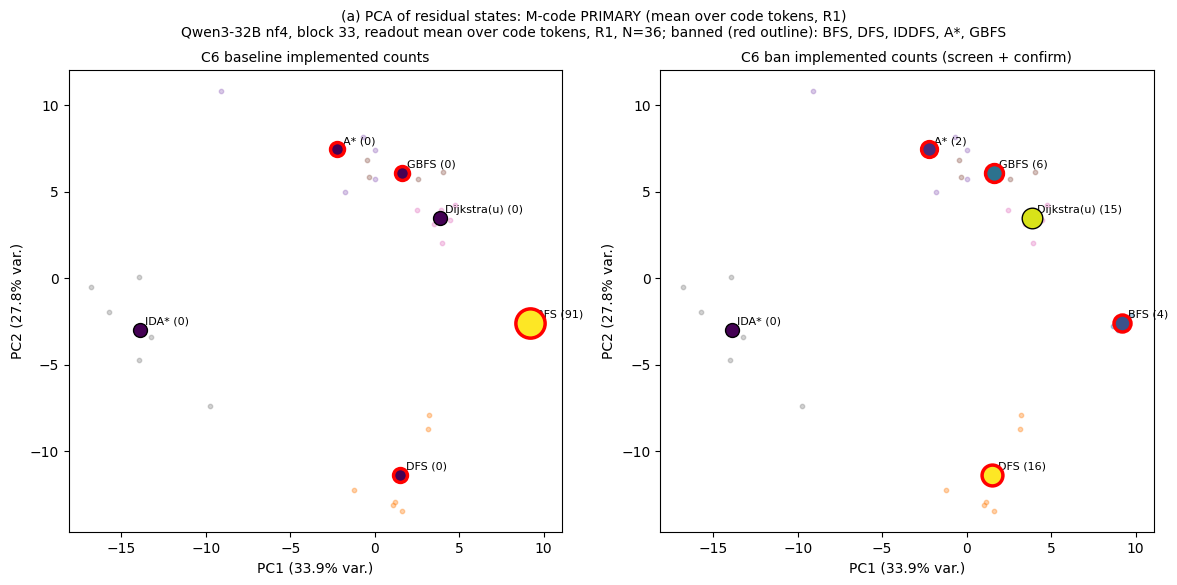

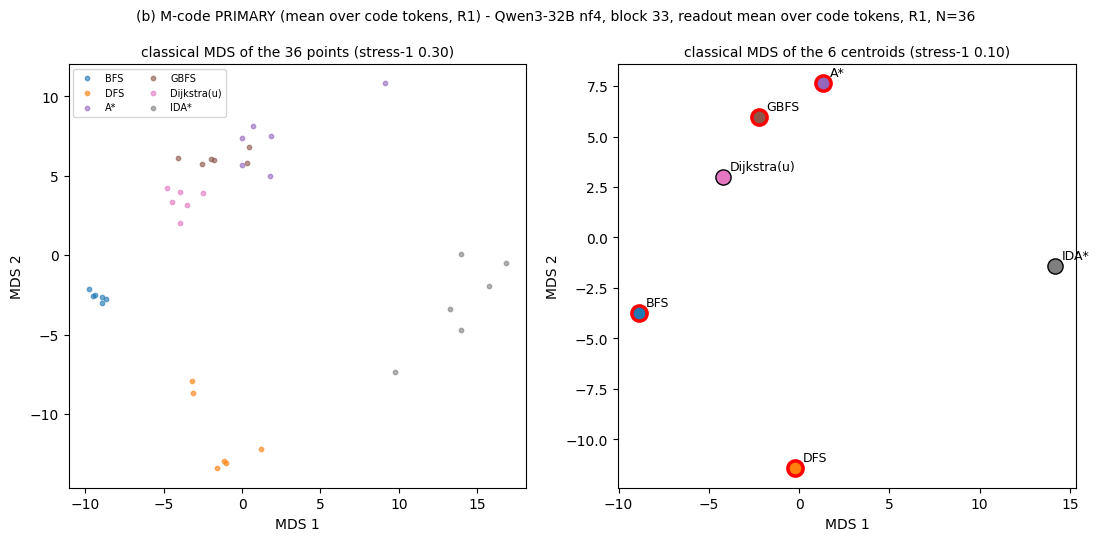

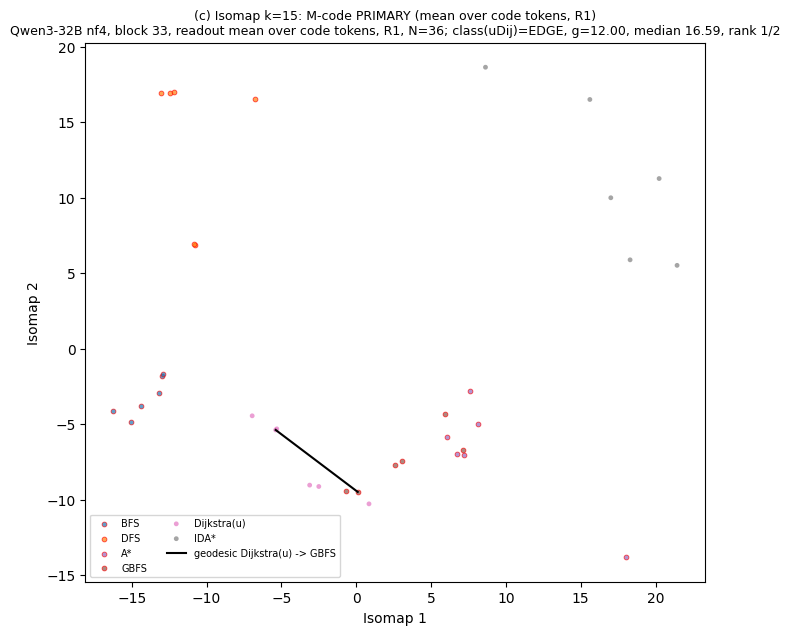

In [20]:
manifold_figs("32b", "mcode_PRIMARY_R1", geo_results["32b|mcode_PRIMARY_R1"])

### Class table, RDMs and the alias-level lexical plot

* **Class table:** EDGE / MIDDLE / OPPOSITE and g/median for every non-banned algorithm in each manifold.
* **RDM heatmaps:** the model RDMs next to the neural class-geodesic RDMs.
* **Behavioural MDS:** drawn in *behavioural* coordinates, not activations.
* **Lexical scatter:** g_alias against L1 on M-name.

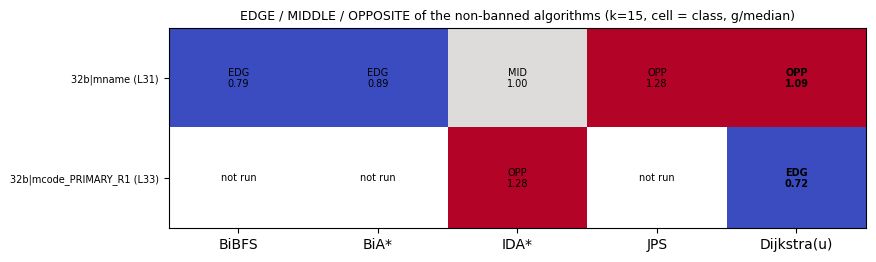

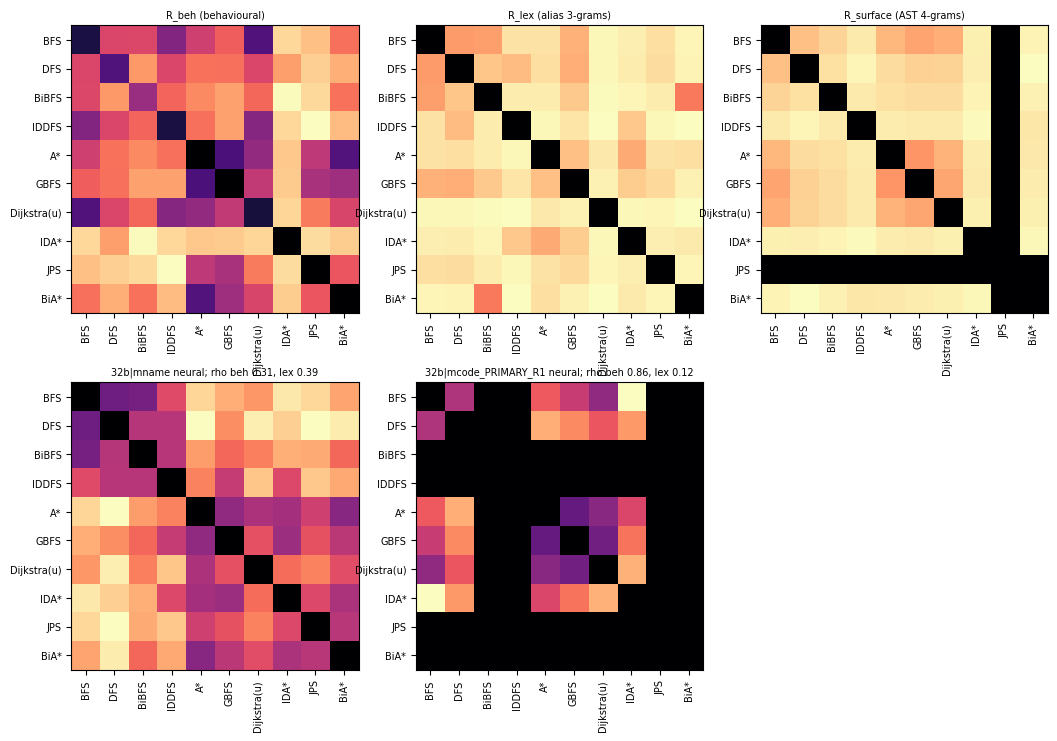

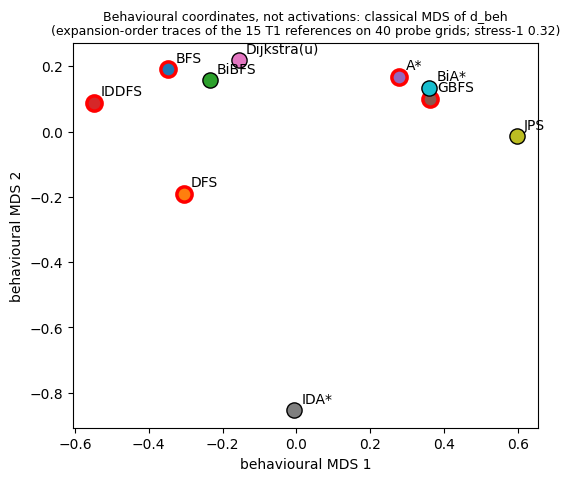

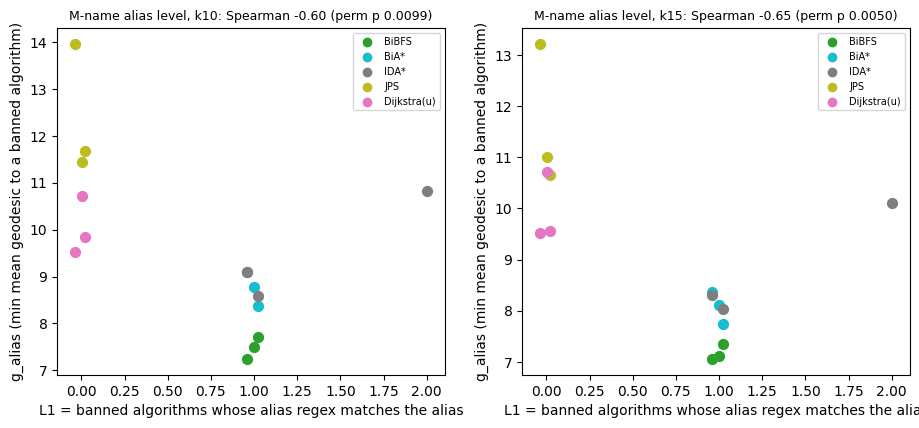

20:04:44|INFO   |figures: 10 PNG files


In [21]:
class_table(geo_results)
rdm_figs()
lexical_fig()
logger.info(f"figures: {len(list(FIG.glob('*.png')))} PNG files")

## Results: this demo next to the full run

The demo runs on a subset of the points, with the Monte-Carlo sizes from the config cell, so its numbers are not the full run's. The comparison shows how much of the full-run picture survives on the subset. The full-run values are the artifact's `results/*.json`, copied into `metadata.full_run_reference`.

In [22]:
ref = data["metadata"]["full_run_reference"]


def _verdict_row(name: str, run: str, n: int, L: int, s: dict, bs: dict, sb: float, n_nb: int,
                 cn: str | None, zs: str | None, eu: str | None) -> dict:
    return {"manifold": name, "run": run, "N": n, "L*": L, "class k10": s["k10"]["udij_class"],
            "class k15": s["k15"]["udij_class"], "rank k15": f"{s['k15']['udij_rank']}/{n_nb}",
            "g/median k15": round(s["k15"]["udij_ratio"], 2), "nearest banned": SHORT[s["k15"]["udij_nearest_banned"]],
            "landing k15": s["k15"]["verdict_pooled"], "bootstrap P(EDGE)": round(bs["edge_probability"][UDIJ], 3),
            "n_boot": bs["n_boot"], "split-half S-B": round(sb, 2), "crossnobis": cn, "z-scored": zs,
            "Euclid. centroid": eu}


rows = []
for name in DEMO_MANIFOLDS:
    r = geo_results[f"32b|{name}"]
    ls, d = r["L_star"], r["L_star"]["describe"]
    rows.append(_verdict_row(name, "demo (subset)", d["n_points"], ls["block"], r["summary"], ls["bootstrap"]["k15"],
                             ls["split_half"]["k15"]["spearman_brown"], len(d["nonbanned_used"]),
                             ls["crossnobis"]["classes"].get(UDIJ), ls["zscored"]["classes"].get(UDIJ),
                             d["euclid_centroid"]["classes"].get(UDIJ)))
    f = ref[name]
    rows.append(_verdict_row(name, "full run", f["n_points"], f["block"], f["summary"], f["bootstrap_k15"],
                             f["split_half_k15_spearman_brown"], len(f["g_k15"]), f["crossnobis_classes"].get(UDIJ),
                             f["zscored_classes"].get(UDIJ), f["euclid_centroid_classes"].get(UDIJ)))
print("Where unit-weight Dijkstra (the survivor) sits relative to the banned five")
display(pd.DataFrame(rows).set_index(["manifold", "run"]))

rsa_rows = []
for name in DEMO_MANIFOLDS:
    dm, fm = rsa_results[f"32b|{name}"]["models"], ref[name]["rsa"]
    for mn in ("R_lex", "R_beh", "R_surface", "R_len"):
        if mn in dm:
            rsa_rows.append({"manifold": name, "model RDM": mn,
                             "demo: rho (exact p)": f"{dm[mn]['rho']:.2f} ({dm[mn]['p_exact']:.3f})",
                             "full run: rho (exact p)": f"{fm[mn]['rho']:.2f} ({fm[mn]['p_exact']:.3f})"})
print("RSA of the class geodesic RDM (k = 15) against the model RDMs")
display(pd.DataFrame(rsa_rows).set_index(["manifold", "model RDM"]))

lr, flr = lex_results["32b|mname"], ref["lexical_regression_mname"]
pl, fpl = pl_results["32b|mcode_PRIMARY_R1"], ref["placement_mcode_PRIMARY_R1"]
ne = ref["name_evocation_32b"]
print(f"P4  lexical, M-name Spearman(g_alias, L1) k10 / k15: demo {lr['k10']['spearman_L1']:.2f} / "
      f"{lr['k15']['spearman_L1']:.2f} (pass {lr['P4_pass']}); full run {flr['k10']['spearman_L1']:.2f} / "
      f"{flr['k15']['spearman_L1']:.2f} (pass {flr['P4_pass']})")
print(f"P8  M-code leave-one-out placement accuracy: demo {pl['G_place']['loo_accuracy']:.2f} "
      f"(N={geo_results['32b|mcode_PRIMARY_R1']['n_points']}, gate {LOO_GATE}); full run "
      f"{fpl['G_place']['loo_accuracy']:.2f} (N=117); full-run survivor programs placed EDGE: "
      f"{fpl['udij_survivors']['n_edge']}/{fpl['udij_survivors']['n']} (P8 pass {fpl['P8_pass']})")
print(f"     name evocation (full run): probe trained on M-name block 31 -> M-desc balanced acc. "
      f"{ne['mdesc']['transfer_balanced_accuracy']:.2f} (chance {ne['mdesc']['chance']:.2f}), M-code "
      f"{ne['mcode_PRIMARY_R1']['transfer_balanced_accuracy']:.2f} (chance {ne['mcode_PRIMARY_R1']['chance']:.2f})")
n4 = ref["n4"]
print(f"\nFull-run named outcome: {n4['named_outcome']} (M-code class k15 {n4['mcode_class_k15']}, M-desc class k15 "
      f"{n4['mdesc_class_k15']}, M-code source robustness {n4['mcode_source_robustness']}, k-sensitive {n4['k_sensitive']})")
print("Full-run predictions pass:", n4["predictions_pass"])
print(n4["statement"])

Where unit-weight Dijkstra (the survivor) sits relative to the banned five


N  L* class k10 class k15 rank k15  g/median k15 nearest banned landing k15  bootstrap P(EDGE)  n_boot  split-half S-B crossnobis  z-scored Euclid. centroid
manifold         run                                                                                                                                                                          
mname            demo (subset)   60  31  OPPOSITE  OPPOSITE      4/5          1.09             A*    OPPOSITE                0.0    1000            0.99   OPPOSITE  OPPOSITE         OPPOSITE
                 full run       300  31  OPPOSITE  OPPOSITE      5/5          1.63             A*    OPPOSITE                0.0    1000            0.99   OPPOSITE  OPPOSITE         OPPOSITE
mcode_PRIMARY_R1 demo (subset)   36  33      EDGE      EDGE      1/2          0.72           GBFS        EDGE                1.0    1000            0.99       EDGE      EDGE             EDGE
                 full run       117  33      EDGE      EDGE      1/2          0.67           GBFS        EDGE                1.0    1000            0.99       EDGE      EDGE             EDGE

RSA of the class geodesic RDM (k = 15) against the model RDMs


demo: rho (exact p) full run: rho (exact p)
manifold         model RDM                                            
mname            R_lex            0.39 (0.003)            0.46 (0.003)
                 R_beh            0.31 (0.025)            0.24 (0.091)
                 R_surface       -0.08 (0.700)            0.20 (0.128)
                 R_len            0.31 (0.035)            0.07 (0.297)
mcode_PRIMARY_R1 R_lex            0.12 (0.331)            0.29 (0.164)
                 R_beh            0.86 (0.003)            0.64 (0.018)
                 R_surface        0.85 (0.001)            0.67 (0.010)
                 R_len            0.90 (0.001)            0.78 (0.007)

P4  lexical, M-name Spearman(g_alias, L1) k10 / k15: demo -0.60 / -0.65 (pass True); full run -0.74 / -0.65 (pass True)
P8  M-code leave-one-out placement accuracy: demo 0.78 (N=36, gate 0.7); full run 0.85 (N=117); full-run survivor programs placed EDGE: 15/15 (P8 pass True)
     name evocation (full run): probe trained on M-name block 31 -> M-desc balanced acc. 0.69 (chance 0.11), M-code 0.17 (chance 0.17)

Full-run named outcome: MIXED (M-code class k15 EDGE, M-desc class k15 OPPOSITE, M-code source robustness ROBUST, k-sensitive False)
Full-run predictions pass: {'P1': False, 'P2': False, 'P3': True, 'P4': True, 'P5': None, 'P6': True, 'P7': None, 'P8': True}
The geometry is correlational: it describes where representations and survivors sit, not whether the model uses this geometry to choose an algorithm (iteration 7's in-manifold pushes moved 0/300).


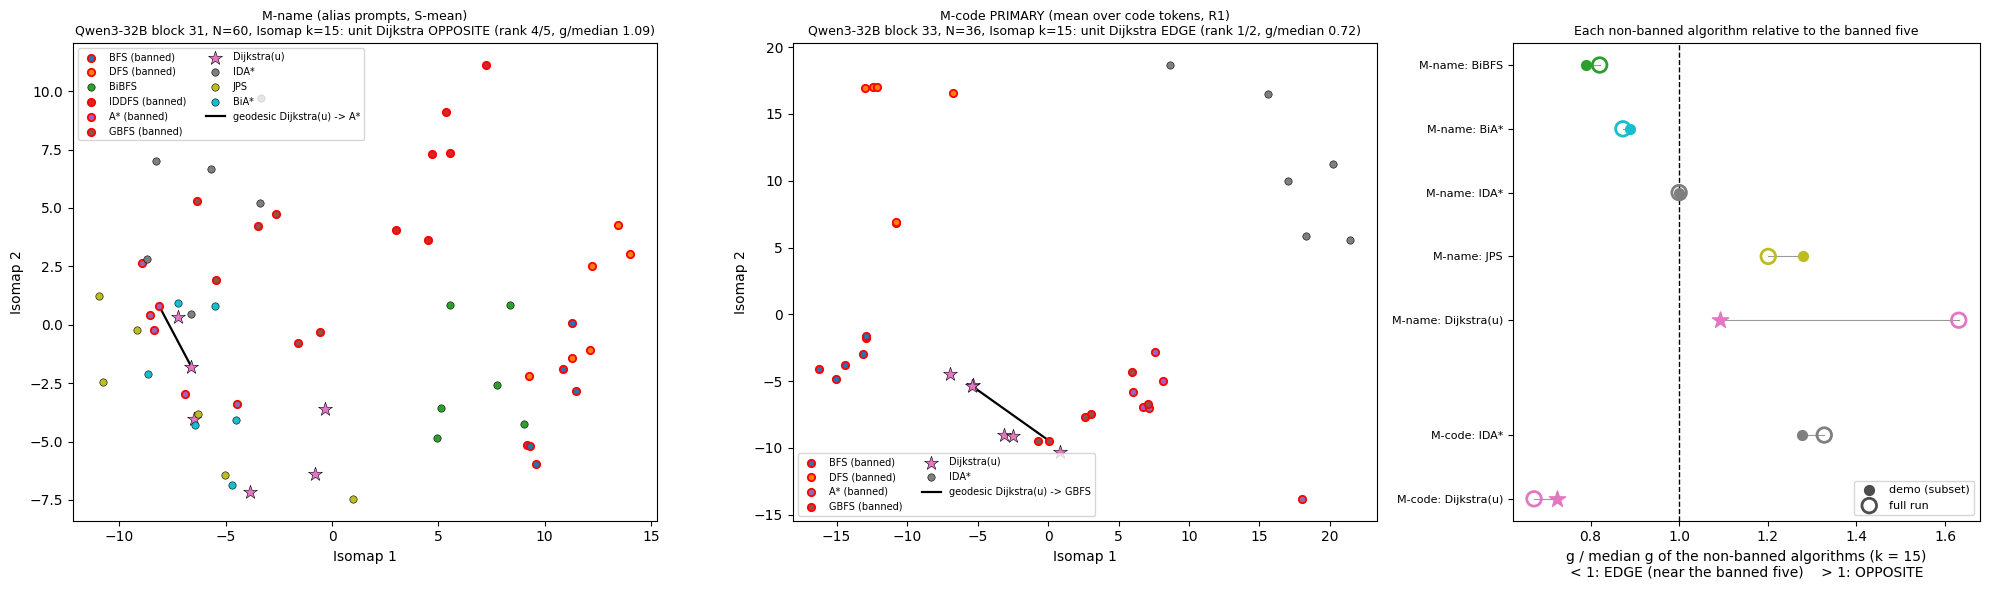

In [23]:
# Summary figure: the two manifolds side by side in activation space (Isomap of the demo points, with the geodesic
# from unit Dijkstra to its nearest banned algorithm), and every non-banned algorithm's g/median (demo vs full run)
fig, axes = plt.subplots(1, 3, figsize=(20, 6), gridspec_kw={"width_ratios": [1, 1, 0.8]})
for ax, name in zip(axes[:2], DEMO_MANIFOLDS):
    z = COORDS[("32b", name)]
    labels, Y, geo = z["labels"], z["iso"], z["geo"]
    kd = geo_results[f"32b|{name}"]["L_star"]["describe"][f"k{K_VERDICT}"]
    for a in [a for a in CANON_ORDER if a in set(labels.tolist())]:
        s = labels == a
        ax.scatter(Y[s, 0], Y[s, 1], s=110 if a == UDIJ else 28, color=COL[a], marker="*" if a == UDIJ else "o",
                   edgecolors="red" if a in B5 else "black", linewidths=1.3 if a in B5 else 0.4, zorder=3,
                   label=SHORT[a] + (" (banned)" if a in B5 else ""))
    nb = kd["nearest_banned"][UDIJ]
    iu, ib = np.where(labels == UDIJ)[0], np.where(labels == nb)[0]
    i, j = np.unravel_index(np.argmin(geo[np.ix_(iu, ib)]), (len(iu), len(ib)))
    _, pred = shortest_path(FROZEN_GEO[("32b", name, K_VERDICT)]["adjacency"], method="D", directed=False,
                            indices=[iu[i]], return_predecessors=True)
    path, cur = [], ib[j]
    while cur >= 0 and cur != iu[i]:
        path.append(cur)
        cur = pred[0, cur]
    path.append(iu[i])
    ax.plot(Y[path, 0], Y[path, 1], "k-", lw=1.6, zorder=2, label=f"geodesic {SHORT[UDIJ]} -> {SHORT[nb]}")
    ax.set_title(f"{TITLES[name]}\nQwen3-32B block {int(z['block'])}, N={len(labels)}, Isomap k={K_VERDICT}: unit "
                 f"Dijkstra {kd['classes'][UDIJ]} (rank {kd['udij_rank']}/{len(kd['g'])}, g/median "
                 f"{kd['udij_ratio']:.2f})", fontsize=9)
    ax.set_xlabel("Isomap 1")
    ax.set_ylabel("Isomap 2")
    ax.legend(fontsize=7, ncol=2, loc="best")

ax = axes[2]
yt, ylab, y = [], [], 0
for name in DEMO_MANIFOLDS:
    d, f = geo_results[f"32b|{name}"]["L_star"]["describe"], ref[name]
    for a in d["nonbanned_used"]:
        demo_r, full_r = d["k15"]["g"][a] / d["k15"]["median"], f["g_k15"][a] / f["median_k15"]
        ax.plot([full_r, demo_r], [y, y], color="0.6", lw=0.8, zorder=1)
        ax.scatter([full_r], [y], s=110, facecolors="none", edgecolors=[COL[a]], linewidths=2, zorder=3)
        ax.scatter([demo_r], [y], s=150 if a == UDIJ else 50, color=[COL[a]], marker="*" if a == UDIJ else "o", zorder=4)
        yt.append(y)
        ylab.append(f"{'M-name' if name == 'mname' else 'M-code'}: {SHORT[a]}")
        y += 1
    y += 0.8
ax.axvline(1.0, color="k", ls="--", lw=1)
ax.set_yticks(yt, ylab, fontsize=8)
ax.invert_yaxis()
ax.set_xlabel("g / median g of the non-banned algorithms (k = 15)\n< 1: EDGE (near the banned five)    "
              "> 1: OPPOSITE")
ax.scatter([], [], s=50, color="0.3", label="demo (subset)")
ax.scatter([], [], s=110, facecolors="none", edgecolors="0.3", linewidths=2, label="full run")
ax.legend(fontsize=8, loc="lower right")
ax.set_title("Each non-banned algorithm relative to the banned five", fontsize=9)
plt.tight_layout()
plt.show()

## Reading the results

* **Names put unit Dijkstra opposite.** On the alias-prompt manifold (M-name), unit Dijkstra is OPPOSITE the banned five at every k: rank 4/5 and g/median 1.09 at k = 15, and no bootstrap resample puts it at the EDGE (P(EDGE) = 0). On this subset the signal is weaker than in the full run (rank 5/5, g/median 1.63). The landing test gives OPPOSITE at k = 15 but NEITHER at k = 10.
* **Aliases carry the banned names.** Aliases that match banned names (higher L1) sit closer to the banned clusters: Spearman −0.60 / −0.65 at k = 10 / 15, so P4 passes. The M-name class geometry follows the lexical RDM (ρ 0.39, p 0.003) more than the behavioural one (ρ 0.31, p 0.025).
* **Code puts it at the edge.** On name-scrubbed programs (M-code), unit Dijkstra is EDGE at every k: nearest banned algorithm GBFS, g/median 0.72 at k = 15, P(EDGE) = 1. The class geometry follows the behavioural (ρ 0.86) and surface (ρ 0.85) RDMs, not the lexical one (ρ 0.12). Leave-one-out placement reaches 0.78, above the 0.70 gate; 6 of the 8 misplacements are A* ↔ GBFS.
* **Not reproduced here.** These need data that is not in the mini file:
  * M-desc (name-free descriptions, OPPOSITE in the full run). It is the manifold that makes the full run's named outcome **MIXED** rather than a clean split between names and mechanism.
  * the robustness grid over neighbouring blocks;
  * name evocation;
  * the per-program placement of the 15 survivor programs (15/15 EDGE in the full run).
* **What this does and does not show.** The geometry is correlational. It describes where the representations and the survivor sit; it does not show that the model uses this geometry to choose an algorithm (iteration 7's in-manifold pushes moved 0 of 300 choices).

**Scaling up.** The shipped config already uses every stored point and the original Monte-Carlo sizes. A run over all 300 / 117 points needs the artifact's full `cache/states/`, which stays on the run's storage volume and is not in the repository. With those states, the artifact's own `method.py analyse` produces the full-run numbers shown above.